<a href="https://colab.research.google.com/github/bbykarisha/DLS_CV/blob/main/hw_5_simpsons_classification_update.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

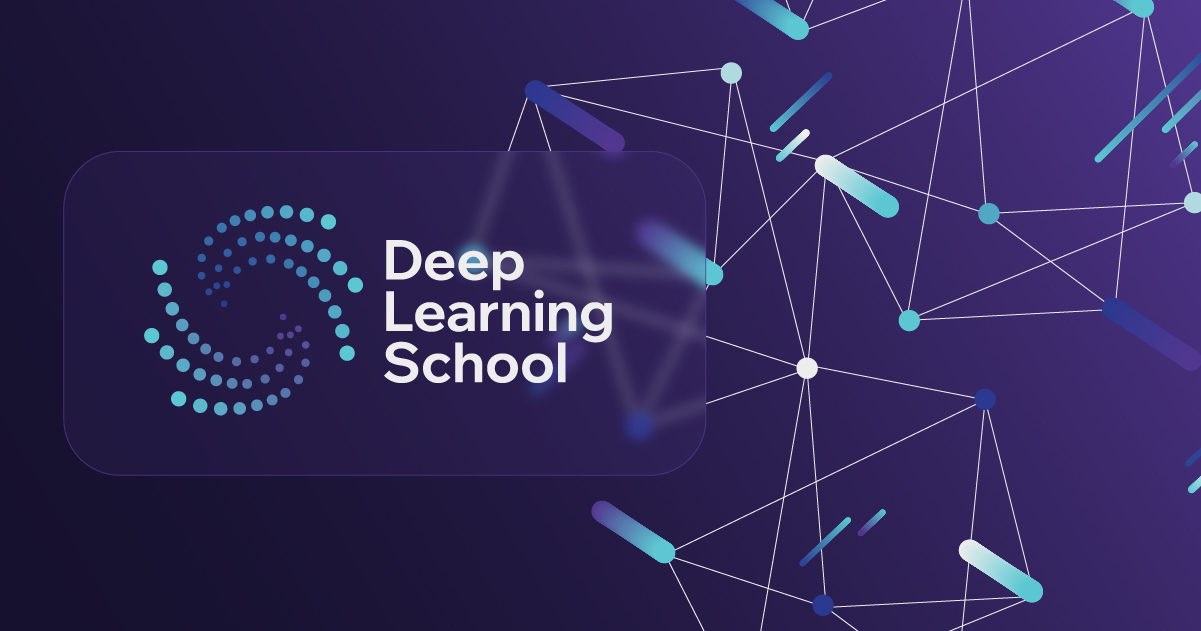


<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h3 style="text-align: center;"><b>Домашнее задание. Классификация изображений</b></h3>


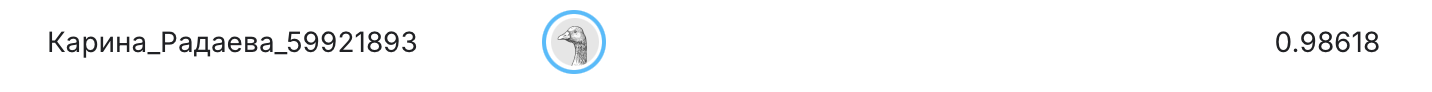

# Домашнее задание. Классификация изображений

Сегодня вам предстоить помочь телекомпании FOX в обработке их контента. Как вы знаете, сериал "Симпсоны" идет на телеэкранах более 25 лет, и за это время скопилось очень много видеоматериала. Персонажи менялись вместе с изменяющимися графическими технологиями, и Гомер Симпсон-2018 не очень похож на Гомера Симпсона-1989. В этом задании вам необходимо классифицировать персонажей, проживающих в Спрингфилде. Думаю, нет смысла представлять каждого из них в отдельности.



В нашем тесте будет 991 картинка, для которых вам будет необходимо предсказать класс.

## Шаг 1. Установка зависимостей

#### Установим необходимые библиотеки и проверим доступность CUDA

In [ ]:
# we will verify that GPU is enabled for this notebook
# following should print: CUDA is available!  Training on GPU ...
#
# if it prints otherwise, then you need to enable GPU:
# from Menu > Runtime > Change Runtime Type > Hardware Accelerator > GPU

import torch
import numpy as np

train_on_gpu = torch.cuda.is_available()

if not train_on_gpu:
    print('CUDA is not available.  Training on CPU ...')
else:
    print('CUDA is available!  Training on GPU ...')

CUDA is available!  Training on GPU ...


In [ ]:
!pip install nvidia-smi

In [ ]:
import pickle
import numpy as np
import pandas as pd
from skimage import io

from tqdm import tqdm, tqdm_notebook
from PIL import Image
from pathlib import Path

from torchvision import transforms
from torchvision.transforms import v2

import torchsummary

from multiprocessing.pool import ThreadPool
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn

from matplotlib import colors, pyplot as plt
%matplotlib inline

# в sklearn не все гладко, чтобы в colab удобно выводить картинки
# мы будем игнорировать warnings
import warnings
warnings.filterwarnings(action='ignore', category=DeprecationWarning)


#### Проверим версии Python и библиотек
Посмотрим, какие версии установлены:

In [ ]:
!python --version
from importlib.metadata import version
for b in ['torch', 'torchvision', 'tqdm', 'matplotlib', 'seaborn', 'Pillow']:
    print(b + ' version: '+ version(b))

Python 3.12.12
torch version: 2.8.0+cu126
torchvision version: 0.23.0+cu126
tqdm version: 4.67.1
matplotlib version: 3.10.0
seaborn version: 0.13.2
Pillow version: 11.3.0


Сверим с версиями питона и библиотек, на которых работал эталонный ноутбук:

- Python 3.12.12
- torch version: 2.8.0+cu126
- torchvision version: 0.23.0+cu126
- tqdm version: 4.67.1
- matplotlib version: 3.10.0
- seaborn version: 0.13.2
- Pillow version: 11.3.0


 #### Определим константы, которые будем использовать по ходу ноутбука

In [ ]:
# разные режимы датасета
DATA_MODES = ['train', 'val', 'test']

# работаем на видеокарте
DEVICE = torch.device("cuda")

#определим директории с тренировочными и тестовыми файлами
TRAIN_DIR = Path('/content/train') #Path('./data/train/')
TEST_DIR = Path('/content/testset') #Path('./data/testset')

# параметры нормировки изображений по трем каналам перед подачей в модель
NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD = [0.229, 0.224, 0.225]

# все изображения будут масштабированы к размеру 224x224 px
RESCALE_SIZE = [224, 224]

## Шаг 2. Загрузка и обработка данных

#### Скачаем изображения по ссылке

In [ ]:
!gdown 1RxBQiZgRAfio2tWhEE7lzZ6IaJzLheH1

Failed to retrieve file url:

	Too many users have viewed or downloaded this file recently. Please
	try accessing the file again later. If the file you are trying to
	access is particularly large or is shared with many people, it may
	take up to 24 hours to be able to view or download the file. If you
	still can't access a file after 24 hours, contact your domain
	administrator.

You may still be able to access the file from the browser:

	https://drive.google.com/uc?id=1RxBQiZgRAfio2tWhEE7lzZ6IaJzLheH1

but Gdown can't. Please check connections and permissions.


In [ ]:
!unzip -q /content/journey-springfield.zip

Посмотрите на структуру файлов в папках train и testset.

В train лежат данные, которые мы будем использовать для обучения модели. Изображения персонажей разложены по папкам, которые названы по именам персонажей. Названия папок мы в дальнейшем будет использовать в качестве текстовых меток классов.

В testset находятся изображения, для которых вам надо будет сделать прогноз наиболее вероятного класса.


Для обращения к файлам сформируем списки имен файлов обучающей+валидационнной и тестовой выборок. Это полные имена, включающие путь к файлам.


In [ ]:
train_val_files = sorted(list(TRAIN_DIR.rglob('*.jpg')))
test_files = sorted(list(TEST_DIR.rglob('*.jpg')))

Кодировать имена персонажей в числовые метки класса и обратно будем при помощи `LabelEncoder`.

Для train выборки сформируем список текстовых меток всех изображений - имя родительской директории, которая одновременно является и именем персонажа. Зададим числовые метки классов нашего энкодера при помощи метода `fit`.

Далее будем применять метод `transform` для преобразования текстовых меток в числовые, и метод `inverse_transform` для преобразования числовых меток в текстовые.


In [ ]:
train_val_labels = [path.parent.name for path in train_val_files]

In [ ]:
np.unique(train_val_labels)

array(['abraham_grampa_simpson', 'agnes_skinner',
       'apu_nahasapeemapetilon', 'barney_gumble', 'bart_simpson',
       'carl_carlson', 'charles_montgomery_burns', 'chief_wiggum',
       'cletus_spuckler', 'comic_book_guy', 'disco_stu', 'edna_krabappel',
       'fat_tony', 'gil', 'groundskeeper_willie', 'homer_simpson',
       'kent_brockman', 'krusty_the_clown', 'lenny_leonard',
       'lionel_hutz', 'lisa_simpson', 'maggie_simpson', 'marge_simpson',
       'martin_prince', 'mayor_quimby', 'milhouse_van_houten',
       'miss_hoover', 'moe_szyslak', 'ned_flanders', 'nelson_muntz',
       'otto_mann', 'patty_bouvier', 'principal_skinner',
       'professor_john_frink', 'rainier_wolfcastle', 'ralph_wiggum',
       'selma_bouvier', 'sideshow_bob', 'sideshow_mel', 'snake_jailbird',
       'troy_mcclure', 'waylon_smithers'], dtype='<U24')

In [ ]:
label_encoder = LabelEncoder()
label_encoder.fit(train_val_labels)

LabelEncoder()

Разделим train выборку на обучающую и валидационнную части. Для того, чтобы персонажи были пропорционально представлены в обучающей и валидационнной подвыборках, применим стратификацию по меткам класса.

In [ ]:
from sklearn.model_selection import train_test_split

train_files, val_files = train_test_split(train_val_files, test_size=0.25, stratify=train_val_labels)

#### Создадим Datasets и Dataloaders

Полезная статья, которой мы вдохновились при создании класса `SimpsonsDataset`:
https://jhui.github.io/2018/02/09/PyTorch-Data-loading-preprocess_torchvision/


У нас есть набор файлов-картинок, которые требуется преобразовать в тензоры, и добавить к ним числовые метки классов. Реализуем это с помощью созданного нами класса `SimpsonsDataset`, который из списка файлов создаст необходимый нам Dataset.  

Будем действовать согласно инструкции из документации (https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html#creating-a-custom-dataset-for-your-files):
- наш класс будет наследовать от класса Dataset
- мы переопределим методы `__init__`, `__len__` и `__getitem__`, а также для удобства добавим несколько методов для загрузки и преобразования изображений.

Важно разобраться, что делает метод self.transform_images_to_tensors().

`Compose` объединяет последовательность следующих преобразований:
- `PILToTensor` конвертирует  `PIL Image` в тензор с параметрами в диапазоне $[0, 255]$ (как все пиксели в исходном изображении)
- `ToDtype` преобразует тензор в `FloatTensor` размера ($C \times H \times W$) со значениями пикселей в диапазоне $[0,1]$
- затем `Normalize` производится масштабирование:
$\text{input} = \frac{\text{input} - \text{mean}}{\text{std}} $, <br>      где константы mean и std - средние и дисперсии по каналам в датасете ImageNet
- наконец, `Resize` преобразует картинки к размеру $224 \times 224$ (в описании датасета указано, что картинки разного размера, так как брались напрямую с видео, поэтому следует привести их к одному размеру).

Сейчас аугментация изображений не производится, поэтому для обучающих и валидационных/тестовых изображений производится одинаковая трансформация. В дальнейшем, если вы захотите добавить аугментацию, вы можете сделать это, например, модифицировав метод `transform_images_to_tensors`. Подробнее про трансформацию изображений вы можете почитать в документации: https://docs.pytorch.org/vision/main/transforms.html


In [ ]:
class SimpsonsDataset(Dataset):
    def __init__(self, files, label_encoder, mode):
        super().__init__()
        # список файлов для загрузки
        self.files = sorted(files)
        # режим работы
        self.mode = mode
        if self.mode not in DATA_MODES:
            print(f"{self.mode} is not correct; correct modes: {DATA_MODES}")
            raise NameError

        self.label_encoder = label_encoder
        self.len_ = len(self.files)

    def __len__(self):
        # сейчас self.__len__() возвращает количество картинок, подаваемых на вход.
        # Если вы решите перевзвесить размеры категорий внутри класса -
        # не забудьте изменить вывод self.__len__()
        return self.len_

    def __getitem__(self, index):
        x = self.load_image(self.files[index])
        x = self.transform_images_to_tensors(x)

        if self.mode == 'test':
            return x
        else:
            path = self.files[index]
            y = self.label_encoder.transform([path.parent.name,]).item()
            return x, y

    # принимает путь к файлу изображения и возвращает само изображение
    def load_image(self, file):
        image = Image.open(file)
        image.load()
        return image

    # преобразует изображение в тензор
    def transform_images_to_tensors(self, image):
      if self.mode == 'train':
        transform = v2.Compose([
            v2.PILToTensor(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
            # добавим аугментацию
            # v2.ColorJitter(brightness = 0.8, contrast = 0.1, saturation = 0.1),
            # v2.RandomHorizontalFlip(p=0.5),
            v2.Resize(RESCALE_SIZE),
          ])
      else:
        transform = v2.Compose([
            v2.PILToTensor(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
            v2.Resize(RESCALE_SIZE),
          ])

      tensor_transformed = transform(image)
      return(tensor_transformed)


In [ ]:
train_dataset = SimpsonsDataset(train_files, label_encoder = label_encoder, mode='train')
val_dataset = SimpsonsDataset(val_files, label_encoder, mode='val')

In [ ]:
batch_size = 64

In [ ]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
loaders = {'train': train_loader, 'val': val_loader}

#### Посмотрим на изображения персонажей

Напишем функцию для визуализации картинок. Это аналог Imshow, которая будет принимать на вход тензоры

In [ ]:
def imshow(inp, title=None, plt_ax=plt, default=False):
    """Imshow для тензоров"""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt_ax.imshow(inp)
    if title is not None:
        plt_ax.set_title(title)
    plt_ax.grid(False)

Проверим, как работает наша функция. Возьмем один батч из лоадера и подадим на вход функции первый тензор из этого батча. Заодно посмотрим, как работает кодировщик меток класса.

Числовая метка класса: 4
Текстовая метка класса: ['bart_simpson']


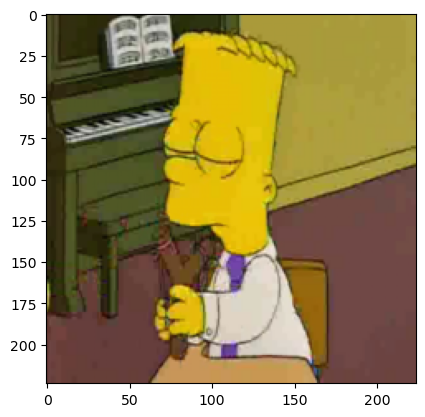

In [ ]:
image_tensor, label = next(iter(train_loader))
print(f"Числовая метка класса: {label[0]}")
print(f"Текстовая метка класса: {label_encoder.inverse_transform([label[0],])}")
imshow(image_tensor[0])


In [ ]:
# uncomment if you have problem with pillow
# def register_extension(id, extension): Image.EXTENSION[extension.lower()] = id.upper()
# Image.register_extension = register_extension
# def register_extensions(id, extensions):
#     for extension in extensions: register_extension(id, extension)
# Image.register_extensions = register_extensions

Давайте посмотрим на наших героев внутри датасета.

In [ ]:
def show_images(n_rows, n_cols, dataset):
  # функция выводит изображения в n_rows рядов и n_cols столбцов
  fig, ax = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(n_cols * 4, n_rows * 4), \
                        sharey=True, sharex=True)

  for fig_x in ax.flatten(): # цикл повторяется (n_rows * n_cols) раз
    random_characters = int(np.random.uniform(0, len(dataset))) # берем случайное число в диапазоне [0; len(dataset))
    im_val, label = dataset[random_characters] # получаем изображение (тензорная форма)
    img_label = " ".join(map(lambda x: x.capitalize(), \
                             label_encoder.inverse_transform([label])[0].split('_')))  # числовую метку класса преобразуем в текстовую и немного отформатируем
    imshow(im_val.data.cpu(), title=img_label, plt_ax=fig_x) # отобразим изображение и метку класса с помощью написанной ранее функции imshow()
    fig_x.set_axis_off()
  return None

**!** Обратите внимание, что возможно, датасет требует дополнительной фильтрации, так как лейблы не всегда точно соответствуют картинкам. Очистка датасета - это один из способов повысить качество модели. Этим можно будет заняться во второй части домашнего задания.

Запустим написанную функцию.

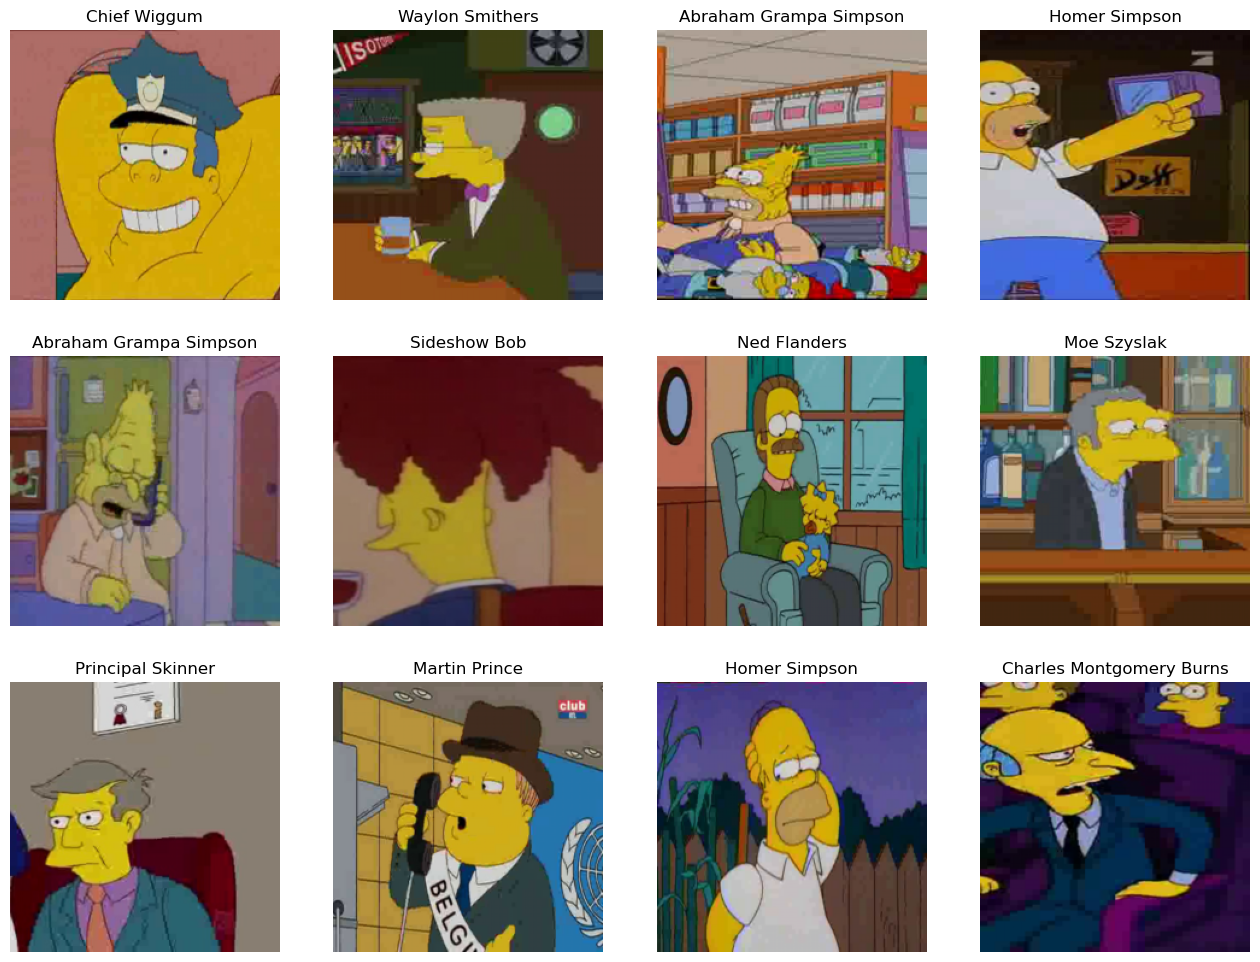

In [ ]:
show_images(n_rows = 3, n_cols = 4, dataset = val_dataset)

## Шаг 3. Построение нейросети

Запустить данную сеть будет вашим мини-заданием на первую неделю, чтобы было проще участвовать в соревновании.

Данная архитектура будет очень простой и нужна для того, чтобы установить базовое понимание и получить простенький сабмит на Kaggle.

О том, как работают свёртки подробней можно прочитать в документации Pytorch на функцию `Conv2d`:

https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html

Калькулятор свёрток:

https://madebyollin.github.io/convnet-calculator/

#### Модель

In [ ]:
class SimpleCnn(nn.Module):
    """
    Очень простая сверточная нейронная сеть для классификации изображений.

    Эта сеть состоит из пяти сверточных слоев, каждый из которых
    включает в себя операцию свертки, функцию активации ReLU и операцию
    пулинга (max-pooling). На выходе используется полносвязный слой
    для классификации на заданное количество классов.

    Параметры:
    ----------
    n_classes : int
        Количество классов для классификации.

    Примечание:
    ----------
    Входные изображения должны иметь размерность (3, H, W), где
    3 - слои rgb для цветной картинки, а H и W - высота и ширина изображения,
    соответственно. Размер выходного тензора будет равен (n_classes).

    Методы:
    -------
    forward(x):
        Пропускает входные данные через сеть и возвращает логиты для
        каждого класса.
    """

    def __init__(self, n_classes):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=8, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv3 = nn.Sequential(
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv4 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv5 = nn.Sequential(
            nn.Conv2d(in_channels=64, out_channels=96, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.out = nn.Linear(96 * 5 * 5, n_classes)


    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.conv5(x)

        x = x.view(x.size(0), -1)
        logits = self.out(x)
        return logits

*Описание слоев*:

1. размерность входа: $3\times 224 \times 224$
2. размерность после 1-го слоя (Conv2d + ReLU + MaxPool2d):  $8 \times 111 \times 111$
3. после 2-го слоя: $16 \times 54 \times 54$
4. после 3-го слоя: $32 \times 26 \times 26$
5. после 4-го слоя: $64 \times 12 \times 12$
6. после 5-го слоя: $96 \times 5 \times 5$
7. после полносвязного слоя (выход модели): количество классов

In [ ]:
model_simple_cnn = SimpleCnn(n_classes = len(np.unique(train_val_labels)))
model_simple_cnn.to(DEVICE)
torchsummary.summary(model_simple_cnn, (3, 224, 224))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1          [-1, 8, 222, 222]             224
              ReLU-2          [-1, 8, 222, 222]               0
         MaxPool2d-3          [-1, 8, 111, 111]               0
            Conv2d-4         [-1, 16, 109, 109]           1,168
              ReLU-5         [-1, 16, 109, 109]               0
         MaxPool2d-6           [-1, 16, 54, 54]               0
            Conv2d-7           [-1, 32, 52, 52]           4,640
              ReLU-8           [-1, 32, 52, 52]               0
         MaxPool2d-9           [-1, 32, 26, 26]               0
           Conv2d-10           [-1, 64, 24, 24]          18,496
             ReLU-11           [-1, 64, 24, 24]               0
        MaxPool2d-12           [-1, 64, 12, 12]               0
           Conv2d-13           [-1, 96, 10, 10]          55,392
             ReLU-14           [-1, 96,

## Шаг 4. Функции для работы с моделью

#### Задание - напишите функции для работы с моделью

Обратите внимание, что метрика, которую необходимо оптимизировать в конкурсе -- `f1-score`.

Ниже приводится код для вычисления целевой метрики.

In [ ]:
from sklearn.metrics import f1_score
# пример расчета: f1 = f1_score(actual_labels, y_predicted, average='micro')

В этом задании может быть полезным сделать, чтобы функция валидации и, возможно, функция обучения на одной эпохе возвращали векторы/тензоры:
- предсказанного наиболее вероятного класса
- и фактических меток класса для каждого объекта.

Сама метрика f1, при этом, будет вычисляться не внутри функции, а вне ее, сопоставляя прогнозные и фактические значения, полученные из вывода функции.

Это поможет проанализировать, при предсказании каких классов модель ошибается чаще. Также такой подход может использоваться для обнаружения изображений, которые модель классифицирует неверно.

Для ускорения вычислений рекомендуется при работе с моделью проводить тензорные вычисления на GPU. Обращаем внимание, для этого необходимо, чтобы и данные, и модель находились на одном устройстве.

Ниже представлен код из предыдущего домашнего задания, который демонстрировал логику циклов обучения и валидации. Ниже в этот код добавлены строки комментарии, показывающие как переносить модель и данные на устройство.


```python
model.to(DEVICE)  # <- переносим модель на устройство DEVICE

for epoch in range(max_epochs):  
    # режим train
    model.train()  
    for x_batch, y_batch in train_dataloader:
        x_batch.to(DEVICE)  # <- переносим тензоры данных на устройство DEVICE
        y_batch.to(DEVICE)  # <- переносим тензоры данных на устройство DEVICE
        
        optimizer.zero_grad()
        outp = model(x_batch)
        loss = criterion(outp, y_batch)
        loss.backward()  
        optimizer.step()
        
        count_metrics(outp, y_batch)  # <-здесь, скорее всего, потребуется перенести данные на cpu, например с помощью метода cpu: metrics.cpu()
     
     # режим test/eval
     model.eval()  
     for x_batch, y_batch in val_dataloader:
        x_batch.to(DEVICE)  # <- переносим тензоры данных на устройство DEVICE
        y_batch.to(DEVICE)  # <- переносим тензоры данных на устройство DEVICE
        
        with torch.no_grad():
            outp = model(x_batch)
            count_metrics(outp, y_batch) # <-здесь, скорее всего, потребуется перенести данные на cpu       
```

Напишите функции:
- для обучения модели на одной эпохе
- для валидации модели на одной эпохе
- для реализации полного цикла обучения

За основу можно взять функции, которые вы написали в предыдущем домашнем задании.

In [ ]:
# YOUR CODE
def fit_one_epoch(model, train_dataloader, optimizer, loss_func):
    losses = []
    true_labels = []
    pred_labels = []

    model.train()

    for X_batch, y_batch in tqdm(train_dataloader):
        true_labels.append(y_batch)
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)

        optimizer.zero_grad()
        outp = model(X_batch)

        loss = loss_func(outp, y_batch)
        losses.append(loss.item())
        loss.backward()

        optimizer.step()

        preds = outp.argmax(-1)
        preds = preds.cpu().detach()
        pred_labels.append(preds)

    mean_loss = np.mean(losses)
    true_labels = torch.cat(true_labels).numpy()
    pred_labels = torch.cat(pred_labels).numpy()

    return true_labels, pred_labels, mean_loss

In [ ]:
# YOUR CODE
def eval_one_epoch(model, val_dataloader, loss_func):
    losses = []
    true_labels = []
    pred_labels = []

    model.eval()

    for X_batch, y_batch in tqdm(val_dataloader):
        true_labels.append(y_batch)
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)

        with torch.no_grad():
            outp = model(X_batch)
            loss = loss_func(outp, y_batch)
            losses.append(loss.item())

            preds = outp.argmax(-1)
            preds = preds.cpu().detach()
            pred_labels.append(preds)

    mean_loss = np.mean(losses)
    true_labels = torch.cat(true_labels).numpy()
    pred_labels = torch.cat(pred_labels).numpy()

    return true_labels, pred_labels, mean_loss

In [ ]:
# YOUR CODE
def train_func(model, num_epochs, dataloaders, optimizer, loss_func, lr_scheduler=None):
    f1_all_epochs = {'train': [], 'val': []}
    loss = {'train': [], 'val': []}

    train_values = {'true': [], 'pred': []}
    val_values = {'true': [], 'pred': []}

    for epoch in range(num_epochs):
        print(f'\nEpoch: {epoch + 1}')
        true_train, pred_train, mean_loss_train = fit_one_epoch(model, dataloaders['train'], optimizer, loss_func)
        f1_train_one_epoch = f1_score(true_train, pred_train, average='micro')
        print(f'\nF1_train: {f1_train_one_epoch}\n')

        true_val, pred_val, mean_loss_val = eval_one_epoch(model, dataloaders['val'], loss_func)
        f1_val_one_epoch = f1_score(true_val, pred_val, average='micro')
        print(f'\nF1_val: {f1_val_one_epoch}\n')

        f1_all_epochs['train'].append(f1_train_one_epoch)
        f1_all_epochs['val'].append(f1_val_one_epoch)

        loss['train'].append(mean_loss_train)
        loss['val'].append(mean_loss_val)

        train_values['true'].append(true_train)
        train_values['pred'].append(pred_train)

        val_values['true'].append(true_val)
        val_values['pred'].append(pred_val)

        if lr_scheduler is not None:
            lr_scheduler.step()

    return f1_all_epochs, loss, train_values, val_values

## Шаг 5. Применение модели к данным

#### Применение модели к данным

In [ ]:
model_simple_cnn = SimpleCnn(n_classes = len(np.unique(train_val_labels)))
model_simple_cnn.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_simple_cnn.parameters(), lr = 1e-3)

Запустите обучение сети

In [ ]:
max_epochs = 20

In [ ]:
# YOUR CODE
f1_values, loss_values, train_values, val_values = train_func(model=model_simple_cnn, num_epochs=max_epochs, \
                                                              dataloaders=loaders, optimizer=optimizer, loss_func=criterion)


Epoch: 1


100%|██████████| 246/246 [01:53<00:00,  2.17it/s]


F1_train: 0.2613542263838461



100%|██████████| 82/82 [00:37<00:00,  2.20it/s]



F1_val: 0.4489873901413833


Epoch: 2


100%|██████████| 246/246 [01:53<00:00,  2.16it/s]


F1_train: 0.559908274412383



100%|██████████| 82/82 [00:37<00:00,  2.19it/s]



F1_val: 0.6303018723729461


Epoch: 3


100%|██████████| 246/246 [01:53<00:00,  2.17it/s]


F1_train: 0.7134212370214663



100%|██████████| 82/82 [00:37<00:00,  2.21it/s]



F1_val: 0.7243026366068017


Epoch: 4


100%|██████████| 246/246 [01:53<00:00,  2.16it/s]


F1_train: 0.798776992165106



100%|██████████| 82/82 [00:36<00:00,  2.24it/s]



F1_val: 0.7523882307986244


Epoch: 5


100%|██████████| 246/246 [01:51<00:00,  2.21it/s]


F1_train: 0.8594177973119307



100%|██████████| 82/82 [00:36<00:00,  2.22it/s]



F1_val: 0.7791364157432175


Epoch: 6


100%|██████████| 246/246 [01:51<00:00,  2.20it/s]


F1_train: 0.8959806357092809



100%|██████████| 82/82 [00:36<00:00,  2.24it/s]



F1_val: 0.7709209017959495


Epoch: 7


100%|██████████| 246/246 [01:51<00:00,  2.20it/s]


F1_train: 0.915408624753169



100%|██████████| 82/82 [00:36<00:00,  2.22it/s]



F1_val: 0.7905999235766145


Epoch: 8


100%|██████████| 246/246 [01:52<00:00,  2.19it/s]


F1_train: 0.9387222116058348



100%|██████████| 82/82 [00:36<00:00,  2.25it/s]



F1_val: 0.7760794803209782


Epoch: 9


100%|██████████| 246/246 [01:51<00:00,  2.21it/s]


F1_train: 0.9463660105739219



100%|██████████| 82/82 [00:36<00:00,  2.22it/s]



F1_val: 0.7896446312571647


Epoch: 10


100%|██████████| 246/246 [01:52<00:00,  2.19it/s]


F1_train: 0.9575132174023823



100%|██████████| 82/82 [00:36<00:00,  2.23it/s]



F1_val: 0.7909820405043944


Epoch: 11


100%|██████████| 246/246 [01:51<00:00,  2.20it/s]


F1_train: 0.9685330275813746



100%|██████████| 82/82 [00:36<00:00,  2.22it/s]



F1_val: 0.7825754680932365


Epoch: 12


100%|██████████| 246/246 [01:52<00:00,  2.18it/s]


F1_train: 0.9661761895662144



100%|██████████| 82/82 [00:36<00:00,  2.23it/s]



F1_val: 0.7930836836071838


Epoch: 13


100%|██████████| 246/246 [01:51<00:00,  2.20it/s]


F1_train: 0.9686604242308428



100%|██████████| 82/82 [00:36<00:00,  2.26it/s]



F1_val: 0.7856324035154757


Epoch: 14


100%|██████████| 246/246 [01:52<00:00,  2.18it/s]


F1_train: 0.9746480667558444



100%|██████████| 82/82 [00:36<00:00,  2.23it/s]



F1_val: 0.7911730989682842


Epoch: 15


100%|██████████| 246/246 [01:51<00:00,  2.20it/s]


F1_train: 0.9768775081215364



100%|██████████| 82/82 [00:36<00:00,  2.23it/s]



F1_val: 0.7993886129155522


Epoch: 16


100%|██████████| 246/246 [01:51<00:00,  2.20it/s]


F1_train: 0.9799350277087713



100%|██████████| 82/82 [00:36<00:00,  2.23it/s]



F1_val: 0.7967137944210928


Epoch: 17


100%|██████████| 246/246 [01:52<00:00,  2.18it/s]


F1_train: 0.9803809159819097



100%|██████████| 82/82 [00:36<00:00,  2.23it/s]



F1_val: 0.7949942682460833


Epoch: 18


100%|██████████| 246/246 [01:51<00:00,  2.21it/s]


F1_train: 0.9810178992292503



100%|██████████| 82/82 [00:36<00:00,  2.22it/s]



F1_val: 0.777034772640428


Epoch: 19


100%|██████████| 246/246 [01:52<00:00,  2.19it/s]


F1_train: 0.9812726925281865



100%|██████████| 82/82 [00:36<00:00,  2.23it/s]



F1_val: 0.780664883454337


Epoch: 20


100%|██████████| 246/246 [01:52<00:00,  2.19it/s]


F1_train: 0.9780877762914836



100%|██████████| 82/82 [00:37<00:00,  2.22it/s]


F1_val: 0.7957585021016431



(опционально) Постройте график динамики метрик модели по ходу обучения

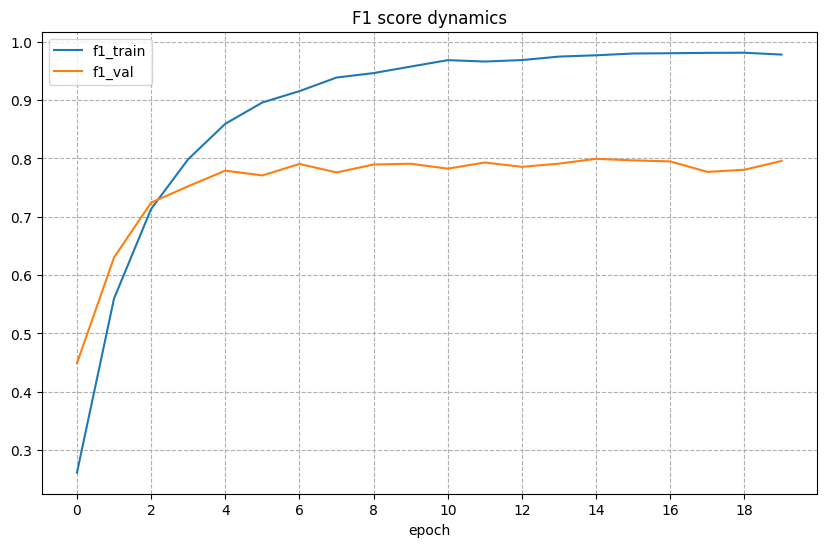

In [ ]:
# YOUR CODE
plt.figure(figsize=(10, 6))
plt.title('F1 score dynamics')

plt.plot(range(max_epochs), f1_values['train'], label='f1_train')
plt.plot(range(max_epochs), f1_values['val'], label='f1_val')

plt.xlabel('epoch')
plt.xticks(range(0, max_epochs, 2))

plt.legend()
plt.grid(linestyle='--')

plt.show()

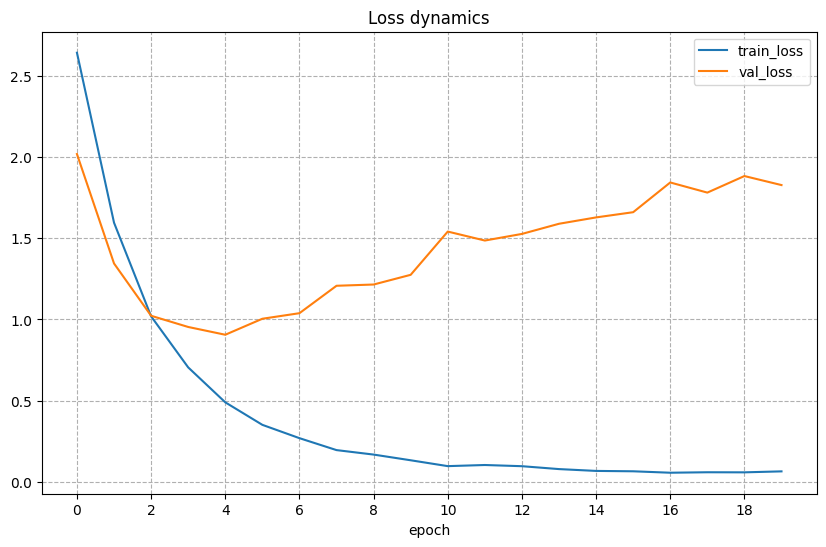

In [ ]:
plt.figure(figsize=(10, 6))
plt.title('Loss dynamics')

plt.plot(range(max_epochs), loss_values['train'], label='train_loss')
plt.plot(range(max_epochs), loss_values['val'], label='val_loss')

plt.xlabel('epoch')
plt.xticks(range(0, max_epochs, 2))

plt.legend()
plt.grid(linestyle='--')

plt.show()

In [ ]:
# сохраняем модель
torch.save(model_simple_cnn.state_dict(), 'simple_cnn_weights.pth')
torch.save(model_simple_cnn, 'entire_simple_cnn.pth')

### Ну и что теперь со всем этим делать?

![alt text](https://www.indiewire.com/wp-content/uploads/2014/08/the-simpsons.jpg)

Сделаем классную визуализацию,  чтобы посмотреть насколько сеть уверена в своих ответах.

In [ ]:
import matplotlib.patches as patches
from matplotlib.font_manager import FontProperties

@torch.no_grad()
def show_images2(n_rows, n_cols, dataset, model):
  # функция выводит изображения в n_rows рядов и n_cols столбцов
  fig, axs = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(n_cols * 4, n_rows * 4), \
                        sharey=True, sharex=True)

  for fig_x in axs.flatten(): # цикл повторяется (n_rows * n_cols) раз
    random_characters = int(np.random.uniform(0, len(dataset))) # берем случайное число в диапазоне [0; len(dataset))
    im_val, label = dataset[random_characters] # выводим изображение (тензорная форма)
    img_label = " ".join(map(lambda x: x.capitalize(), \
                             label_encoder.inverse_transform([label])[0].split('_')))  # числовую метку класса преобразуем в текстовую и немного отформатируем
    imshow(im_val.data.cpu(), title=img_label, plt_ax=fig_x) # отобразим изображение и метку класса с помощью написанной ранее функции imshow()

    # ниже представлен код для добавления на изображение подписи с вероятностью класса
    actual_text = "Actual : {}".format(img_label)


    font0 = FontProperties()
    font = font0.copy()

    # наша модель возвращает логиты, поэтому для получения вероятностей классов не забываем применить softmax:
    prob_pred = nn.functional.softmax(model(im_val.unsqueeze(0).to(DEVICE)), dim = -1).cpu().numpy()

    predicted_proba = np.max(prob_pred)*100 # берем максимальную вероятность класса
    y_pred = np.argmax(prob_pred) # берем числовую метку класса, для которого вероятность максимальна

    predicted_label = " ".join(map(lambda x: x.capitalize(), \
                             label_encoder.inverse_transform([y_pred])[0].split('_')))
    predicted_text = "{}:\n {:.1f}%".format(predicted_label, predicted_proba)

    fig_x.add_patch(patches.Rectangle((0, 190), 7*len(predicted_label), 25,color='white'))
    fig_x.text(2, 195, predicted_text , horizontalalignment='left', fontproperties=font,
                    verticalalignment='top',fontsize=8, color='black',fontweight='bold')
    fig_x.set_axis_off()

  return None

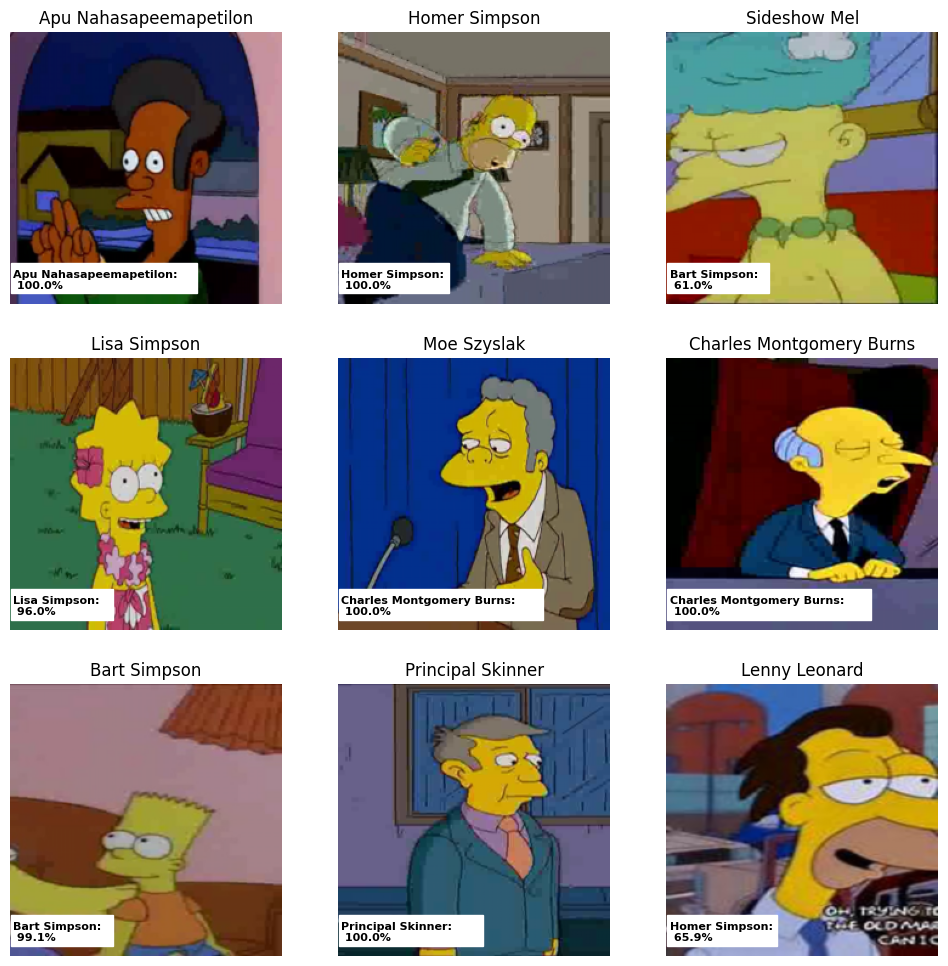

In [ ]:
show_images2(n_rows = 3, n_cols = 3, dataset = val_dataset, model = model_simple_cnn)

## Шаг 6. Submit на Kaggle

![alt text](https://i.redd.it/nuaphfioz0211.jpg)

Создадим loader для тестовых данных

In [ ]:
test_dataset = SimpsonsDataset(test_files, label_encoder = label_encoder, mode="test")
test_loader = DataLoader(test_dataset, shuffle=False, batch_size=64)

Воспользуемся функцией predict, которая возвращает предсказанные числовые метки для всех объектов в лоадере.

In [ ]:
def predict(model, loader):
    model.eval()
    all_predictions = torch.tensor([]).to(DEVICE).int()
    print("Test mode...")

    for inputs in tqdm_notebook(loader):
        inputs = inputs.to(DEVICE)

        with torch.no_grad():
            outputs = model(inputs)

            predictions = outputs.argmax(-1).int()
            all_predictions = torch.cat((all_predictions, predictions), 0)

    return all_predictions.cpu()

Получем предсказание меток классов для тестовых данных:

In [ ]:
predicted_numeric_labels = predict(model_simple_cnn, test_loader)

Test mode...


  0%|          | 0/16 [00:00<?, ?it/s]

и преобразуем их в текстовые метки:

In [ ]:
predicted_text_labels = label_encoder.inverse_transform(predicted_numeric_labels)

Загрузим пример файла для загрузки на Kaggle (проверьте путь, по которому у вас лежит файл sample_submission.csv и при необходимости скорректируйте путь в коде ниже):

In [ ]:
sample_submission = pd.read_csv("/content/sample_submission.csv")
sample_submission.head(10)

,Id,Expected
0,img0.jpg,bart_simpson
1,img1.jpg,bart_simpson
2,img2.jpg,bart_simpson
3,img3.jpg,bart_simpson
4,img4.jpg,bart_simpson
5,img5.jpg,bart_simpson
6,img6.jpg,bart_simpson
7,img7.jpg,bart_simpson
8,img8.jpg,bart_simpson
9,img9.jpg,bart_simpson


In [ ]:
my_submission = pd.DataFrame({'Id': [path.name for path in test_files], 'Expected': predicted_text_labels})
my_submission.head(10)

,Id,Expected
0,img0.jpg,nelson_muntz
1,img1.jpg,bart_simpson
2,img10.jpg,ned_flanders
3,img100.jpg,chief_wiggum
4,img101.jpg,apu_nahasapeemapetilon
5,img102.jpg,kent_brockman
6,img103.jpg,edna_krabappel
7,img104.jpg,chief_wiggum
8,img105.jpg,lisa_simpson
9,img106.jpg,kent_brockman


In [ ]:
# TODO : сделайте сабмит (это важно, если Вы не справляетесь, но дошли до этой ячейки, то сообщите в чат и Вам помогут)

In [ ]:
my_submission.to_csv('simple_cnn_baseline.csv', index=False)

## Приключение?

А теперь самое интересное, мы сделали простенькую сверточную сеть и смогли отправить сабмит, но получившийся score нас явно не устраивает. Надо с этим что-то сделать.

Вам предлагается творческая и исследовательская свобода в том, как вы будете улучшать score модели. Вот некоторые направления, которые вы, возможно, захотите попробовать:
1. Работа с датасетом:
* Попробуйте увеличить разнообразие обучающей выборки при помощи аугментации ([ссылка 1](https://habr.com/ru/companies/smartengines/articles/264677/), [ссылка 2](https://www.geeksforgeeks.org/python-data-augmentation/));
* Используя результаты функции eval_one_epoch, вы можете посмотреть, как метрика f1-score внутри класса связана с размером самого класса в обучающей выборке. Скорее всего, вы заметите прямую зависимость. Решением может быть увеличение размеров слабо представленных классов. Сделать это можно, вручную добавив этот функционал в SimpsonsDataset или воспользовавшись инструментом WeightedRandomSampler.

* Также вы можете изучить, какие изображения модель классифицирует неверно. Можно просто посмотреть неверно классифицированные изображения в валидационном датасете. Можно попробовать более фундаментальный подход - создать dataloader из всех изображений обучающей и валидационной выборки в SimpsonsDataset c режимом 'val', прогнать данные через обученную модель simple_cnn. Более того, можно обучить несколько моделей с разной архитектурой, и прогнать объединенный датасет через все эти модели - и выделить те изображения, в классификации которых ошиблись несколько моделей.

* Это поможет понять, как качество и чистота исходных данных влияет на результаты обучения модели. Если вы обнаружите ошибки в simpsons_dataset и решите их исправить или удалить некоторые изображения из обучающей выборки - сделайте это в ноутбуке, чтобы при проверке можно было повторить результаты работы вашего кода.  

2. Работа с архитектурой сети:
* учим дольше и изменяем (подбираем) гиперпараметры: learning rate, batch size, нормализация картинки и вот это всё;
* добавление/удаление свёрточных и полносвязных слоёв;
* А еще есть где пулинги и батч-норм!

3. Применение техник, описанных в предыдущих пунктах, позволяет добиться довольно высоких результатов. Но вы можете попробовать файнтютинг и трансферлёнинг:
* ну разве это deep learning? Вот ResNet и Inception, которые можно зафайнтьюнить под наши данные, вот это я понимаю (можно и обучить в колабе, а можно и [готовые](https://github.com/Cadene/pretrained-models.pytorch) скачать).

4. Улучшение оптимизации:
* ну разве Адам наше все? [adamW](https://www.fast.ai/2018/07/02/adam-weight-decay/) для практика, [статейка для любителей](https://openreview.net/pdf?id=ryQu7f-RZ) (очень хороший анализ), [наши ](https://github.com/MichaelKonobeev/adashift/) эксперименты для заинтересованных.

5. Наконец, возможно, стоит подумать об ансамблях


Надеюсь, что у Вас получится!

In [ ]:
def plot_training(f1_values, loss_values, max_epochs=20):
    plt.figure(figsize=(10, 12))

    plt.subplot(2, 1, 1)
    plt.title('F1 score dynamics')

    plt.plot(f1_values['train'], label='f1_train')
    plt.plot(f1_values['val'], label='f1_val')

    plt.xlabel('epoch')
    plt.xticks(range(0, max_epochs, 2))

    plt.legend()
    plt.grid(linestyle='--')


    plt.subplot(2, 1, 2)
    plt.title('Loss dynamics')

    plt.plot(loss_values['train'], label='loss_train')
    plt.plot(loss_values['val'], label='loss_val')

    plt.xlabel('epoch')
    plt.xticks(range(0, max_epochs, 2))

    plt.legend()
    plt.grid(linestyle='--')

    plt.show()

Попробуем немного поменять архитектуру сети, добавив BatchNorm и скрытый линейный слой.

In [ ]:
class ModifiedCnn(nn.Module):
    """
    Эта сеть состоит из пяти сверточных слоев, каждый из которых
    включает в себя операцию свертки, функцию активации ReLU, операцию
    пулинга (max-pooling) и BatchNorm, а также скрытого полносвязного слоя.
    На выходе используется полносвязный слой для классификации на заданное
    количество классов.

    Параметры:
    ----------
    n_classes : int
        Количество классов для классификации.

    Примечание:
    ----------
    Входные изображения должны иметь размерность (3, H, W), где
    3 - слои rgb для цветной картинки, а H и W - высота и ширина изображения,
    соответственно. Размер выходного тензора будет равен (n_classes).

    Методы:
    -------
    forward(x):
        Пропускает входные данные через сеть и возвращает логиты для
        каждого класса.
    """

    def __init__(self, n_classes):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=8, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.BatchNorm2d(num_features=8)
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.BatchNorm2d(num_features=16)
        )
        self.conv3 = nn.Sequential(
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.BatchNorm2d(num_features=32)
        )
        self.conv4 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.BatchNorm2d(num_features=64)
        )
        self.conv5 = nn.Sequential(
            nn.Conv2d(in_channels=64, out_channels=96, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.BatchNorm2d(num_features=96)
        )

        self.fc = nn.Sequential(
            nn.Linear(in_features=96 * 5 * 5, out_features=120),
            nn.ReLU(),
            nn.BatchNorm1d(120)
        )

        self.out = nn.Linear(in_features=120, out_features=n_classes)


    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.conv5(x)

        x = x.view(x.size(0), -1)
        x = self.fc(x)
        logits = self.out(x)

        return logits

In [ ]:
model_cnn = ModifiedCnn(n_classes = len(np.unique(train_val_labels)))
model_cnn.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_cnn.parameters(), lr = 1e-3)

In [ ]:
torchsummary.summary(model_cnn, (3, 224, 224))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1          [-1, 8, 222, 222]             224
              ReLU-2          [-1, 8, 222, 222]               0
         MaxPool2d-3          [-1, 8, 111, 111]               0
       BatchNorm2d-4          [-1, 8, 111, 111]              16
            Conv2d-5         [-1, 16, 109, 109]           1,168
              ReLU-6         [-1, 16, 109, 109]               0
         MaxPool2d-7           [-1, 16, 54, 54]               0
       BatchNorm2d-8           [-1, 16, 54, 54]              32
            Conv2d-9           [-1, 32, 52, 52]           4,640
             ReLU-10           [-1, 32, 52, 52]               0
        MaxPool2d-11           [-1, 32, 26, 26]               0
      BatchNorm2d-12           [-1, 32, 26, 26]              64
           Conv2d-13           [-1, 64, 24, 24]          18,496
             ReLU-14           [-1, 64,

In [ ]:
f1_values, loss_values, train_values, val_values = train_func(model=model_cnn, num_epochs=max_epochs, dataloaders=loaders, \
                                                              optimizer=optimizer, loss_func=criterion)


Epoch: 1


100%|██████████| 246/246 [01:52<00:00,  2.18it/s]



F1_train: 0.5573603414230206



100%|██████████| 82/82 [00:35<00:00,  2.28it/s]



F1_val: 0.696217042414979


Epoch: 2


100%|██████████| 246/246 [01:49<00:00,  2.24it/s]



F1_train: 0.7606853939741385



100%|██████████| 82/82 [00:36<00:00,  2.26it/s]



F1_val: 0.7430263660680169


Epoch: 3


100%|██████████| 246/246 [01:50<00:00,  2.22it/s]



F1_train: 0.8473788139371935



100%|██████████| 82/82 [00:36<00:00,  2.27it/s]



F1_val: 0.8221245701184563


Epoch: 4


100%|██████████| 246/246 [01:49<00:00,  2.25it/s]



F1_train: 0.9129243900885406



100%|██████████| 82/82 [00:36<00:00,  2.27it/s]



F1_val: 0.8379824226213222


Epoch: 5


100%|██████████| 246/246 [01:51<00:00,  2.21it/s]



F1_train: 0.952863239696796



100%|██████████| 82/82 [00:36<00:00,  2.24it/s]



F1_val: 0.8454337027130302


Epoch: 6


100%|██████████| 246/246 [01:51<00:00,  2.21it/s]



F1_train: 0.9759857315752596



100%|██████████| 82/82 [00:35<00:00,  2.28it/s]



F1_val: 0.8494459304547192


Epoch: 7


100%|██████████| 246/246 [01:51<00:00,  2.21it/s]



F1_train: 0.9863048601821772



100%|██████████| 82/82 [00:36<00:00,  2.25it/s]



F1_val: 0.8484906381352694


Epoch: 8


100%|██████████| 246/246 [01:52<00:00,  2.18it/s]



F1_train: 0.9906363462640932



100%|██████████| 82/82 [00:36<00:00,  2.22it/s]



F1_val: 0.8523118074130684


Epoch: 9


100%|██████████| 246/246 [01:53<00:00,  2.16it/s]



F1_train: 0.989234983119944



100%|██████████| 82/82 [00:36<00:00,  2.22it/s]



F1_val: 0.8551776843714176


Epoch: 10


100%|██████████| 246/246 [01:52<00:00,  2.18it/s]



F1_train: 0.9895534747436142



100%|██████████| 82/82 [00:36<00:00,  2.25it/s]



F1_val: 0.8546045089797478


Epoch: 11


100%|██████████| 246/246 [01:51<00:00,  2.20it/s]



F1_train: 0.9902541563156889



100%|██████████| 82/82 [00:36<00:00,  2.24it/s]



F1_val: 0.8532670997325181


Epoch: 12


100%|██████████| 246/246 [01:51<00:00,  2.20it/s]



F1_train: 0.9887890948468055



100%|██████████| 82/82 [00:36<00:00,  2.24it/s]



F1_val: 0.8492548719908292


Epoch: 13


100%|██████████| 246/246 [01:52<00:00,  2.19it/s]



F1_train: 0.9836932288680807



100%|██████████| 82/82 [00:36<00:00,  2.25it/s]



F1_val: 0.8515475735575087


Epoch: 14


100%|██████████| 246/246 [01:50<00:00,  2.22it/s]



F1_train: 0.9917829161093064



100%|██████████| 82/82 [00:36<00:00,  2.23it/s]



F1_val: 0.8614826136797861


Epoch: 15


100%|██████████| 246/246 [01:51<00:00,  2.20it/s]



F1_train: 0.9947767373718072



100%|██████████| 82/82 [00:36<00:00,  2.24it/s]



F1_val: 0.8586167367214368


Epoch: 16


100%|██████████| 246/246 [01:51<00:00,  2.20it/s]



F1_train: 0.9900630613414867



100%|██████████| 82/82 [00:36<00:00,  2.25it/s]



F1_val: 0.8557508597630875


Epoch: 17


100%|██████████| 246/246 [01:51<00:00,  2.21it/s]



F1_train: 0.9891075864704758



100%|██████████| 82/82 [00:35<00:00,  2.28it/s]



F1_val: 0.8521207489491784


Epoch: 18


100%|██████████| 246/246 [01:51<00:00,  2.20it/s]



F1_train: 0.9915281228103701



100%|██████████| 82/82 [00:36<00:00,  2.24it/s]



F1_val: 0.8589988536492167


Epoch: 19


100%|██████████| 246/246 [01:51<00:00,  2.20it/s]



F1_train: 0.9919740110835085



100%|██████████| 82/82 [00:36<00:00,  2.24it/s]



F1_val: 0.8559419182269774


Epoch: 20


100%|██████████| 246/246 [01:51<00:00,  2.21it/s]



F1_train: 0.9940123574749984



100%|██████████| 82/82 [00:36<00:00,  2.28it/s]


F1_val: 0.853649216660298



In [ ]:
# сохраняем модель
torch.save(model_cnn.state_dict(), 'model_cnn_weights.pth')
torch.save(model_cnn, 'entire_model_cnn.pth')

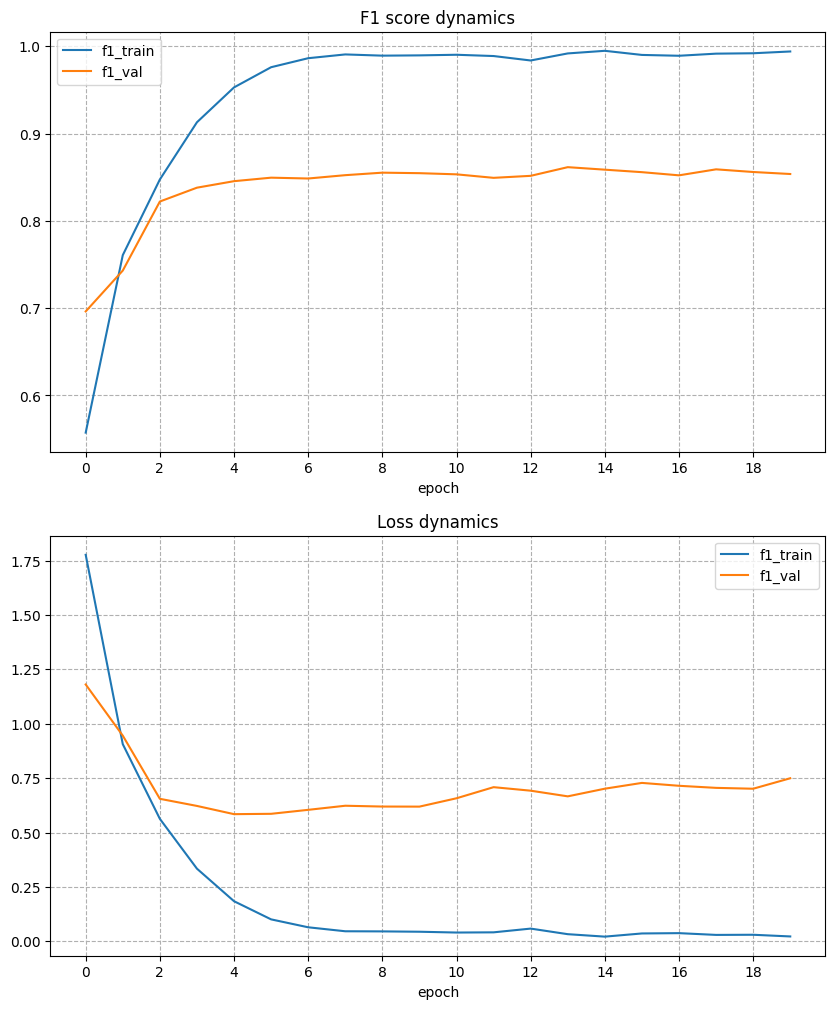

In [ ]:
plot_training(f1_values, loss_values)

In [ ]:
predicted_numeric_labels = predict(model_cnn, test_loader)
predicted_text_labels = label_encoder.inverse_transform(predicted_numeric_labels)

Test mode...


  0%|          | 0/16 [00:00<?, ?it/s]

In [ ]:
modified_submission = pd.DataFrame({'Id': [path.name for path in test_files], 'Expected': predicted_text_labels})
modified_submission.head()

,Id,Expected
0,img0.jpg,nelson_muntz
1,img1.jpg,bart_simpson
2,img10.jpg,ned_flanders
3,img100.jpg,chief_wiggum
4,img101.jpg,apu_nahasapeemapetilon


In [ ]:
modified_submission.to_csv('cnn_baseline.csv', index=False)

Слегка изменив архитектуру сети на тестовом датасете можно добиться качества 0.967

Попробуем добавить аугментацию в виде горизонтального поворота картинки.

In [ ]:
f1_values, loss_values, train_values, val_values = train_func(model=model_cnn, num_epochs=max_epochs, dataloaders=loaders, \
                                                              optimizer=optimizer, loss_func=criterion)


Epoch: 1


100%|██████████| 246/246 [00:41<00:00,  5.99it/s]



F1_train: 0.5580610229950952



100%|██████████| 82/82 [00:11<00:00,  7.19it/s]



F1_val: 0.6822697745510126


Epoch: 2


100%|██████████| 246/246 [00:41<00:00,  5.99it/s]



F1_train: 0.7456525893369005



100%|██████████| 82/82 [00:11<00:00,  7.18it/s]



F1_val: 0.757737867787543


Epoch: 3


100%|██████████| 246/246 [00:41<00:00,  5.93it/s]



F1_train: 0.823428243837187



100%|██████████| 82/82 [00:11<00:00,  7.14it/s]



F1_val: 0.8085594191822698


Epoch: 4


100%|██████████| 246/246 [00:41<00:00,  5.92it/s]



F1_train: 0.8689725460220397



100%|██████████| 82/82 [00:11<00:00,  7.15it/s]



F1_val: 0.8165838746656476


Epoch: 5


100%|██████████| 246/246 [00:41<00:00,  5.89it/s]



F1_train: 0.9026689598063571



100%|██████████| 82/82 [00:11<00:00,  6.90it/s]



F1_val: 0.8454337027130302


Epoch: 6


100%|██████████| 246/246 [00:42<00:00,  5.76it/s]



F1_train: 0.9280845913752468



100%|██████████| 82/82 [00:11<00:00,  7.10it/s]



F1_val: 0.8408482995796713


Epoch: 7


100%|██████████| 246/246 [00:42<00:00,  5.72it/s]



F1_train: 0.9477673737180712



100%|██████████| 82/82 [00:11<00:00,  7.14it/s]



F1_val: 0.861864730607566


Epoch: 8


100%|██████████| 246/246 [00:43<00:00,  5.66it/s]



F1_train: 0.9624179884069048



100%|██████████| 82/82 [00:11<00:00,  7.13it/s]



F1_val: 0.8559419182269774


Epoch: 9


100%|██████████| 246/246 [00:42<00:00,  5.81it/s]



F1_train: 0.9656029046436079



100%|██████████| 82/82 [00:11<00:00,  6.89it/s]



F1_val: 0.8582346197936569


Epoch: 10


100%|██████████| 246/246 [00:42<00:00,  5.75it/s]



F1_train: 0.9710172622460029



100%|██████████| 82/82 [00:11<00:00,  7.42it/s]



F1_val: 0.8601452044325564


Epoch: 11


100%|██████████| 246/246 [00:41<00:00,  5.95it/s]



F1_train: 0.9750302567042487



100%|██████████| 82/82 [00:11<00:00,  7.33it/s]



F1_val: 0.8681696599159343


Epoch: 12


100%|██████████| 246/246 [00:41<00:00,  5.96it/s]



F1_train: 0.9784699662398879



100%|██████████| 82/82 [00:11<00:00,  7.34it/s]



F1_val: 0.8698891860909438


Epoch: 13


100%|██████████| 246/246 [00:41<00:00,  5.94it/s]



F1_train: 0.9831199439454742



100%|██████████| 82/82 [00:11<00:00,  7.31it/s]



F1_val: 0.8723729461215132


Epoch: 14


100%|██████████| 246/246 [00:41<00:00,  5.98it/s]



F1_train: 0.9824829606981337



100%|██████████| 82/82 [00:11<00:00,  7.26it/s]



F1_val: 0.8771494077187619


Epoch: 15


100%|██████████| 246/246 [00:42<00:00,  5.79it/s]



F1_train: 0.9881521115994649



100%|██████████| 82/82 [00:11<00:00,  7.21it/s]



F1_val: 0.8714176538020635


Epoch: 16


100%|██████████| 246/246 [00:41<00:00,  5.89it/s]



F1_train: 0.9865596534811134



100%|██████████| 82/82 [00:11<00:00,  7.11it/s]



F1_val: 0.8668322506687046


Epoch: 17


100%|██████████| 246/246 [00:42<00:00,  5.76it/s]



F1_train: 0.9794891394356329



100%|██████████| 82/82 [00:11<00:00,  7.25it/s]



F1_val: 0.8739014138326328


Epoch: 18


100%|██████████| 246/246 [00:42<00:00,  5.80it/s]



F1_train: 0.9847761003885598



100%|██████████| 82/82 [00:11<00:00,  7.26it/s]



F1_val: 0.8681696599159343


Epoch: 19


100%|██████████| 246/246 [00:42<00:00,  5.85it/s]



F1_train: 0.9855404802853684



100%|██████████| 82/82 [00:11<00:00,  7.14it/s]



F1_val: 0.8739014138326328


Epoch: 20


100%|██████████| 246/246 [00:42<00:00,  5.84it/s]



F1_train: 0.9845213070896235



100%|██████████| 82/82 [00:11<00:00,  6.96it/s]


F1_val: 0.8714176538020635



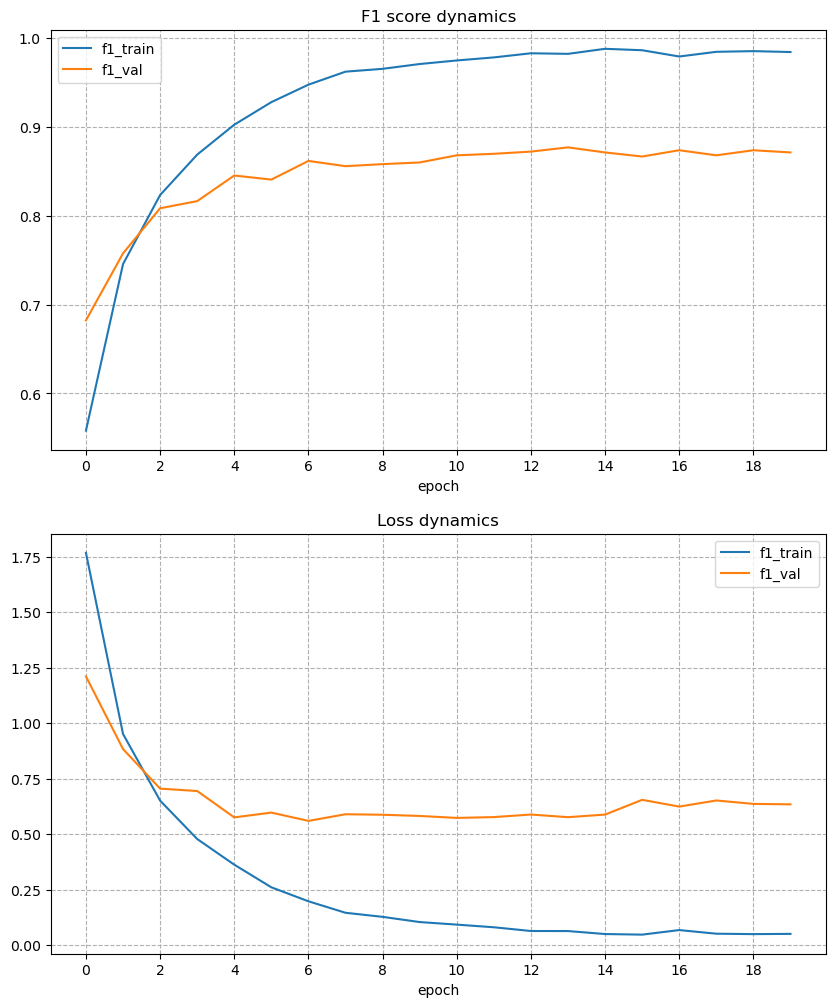

In [ ]:
plot_training(f1_values, loss_values)

In [ ]:
predicted_numeric_labels = predict(model_cnn, test_loader)
predicted_text_labels = label_encoder.inverse_transform(predicted_numeric_labels)

Test mode...


  0%|          | 0/16 [00:00<?, ?it/s]

In [ ]:
modified_submission = pd.DataFrame({'Id': [path.name for path in test_files], 'Expected': predicted_text_labels})
modified_submission.head()

,Id,Expected
0,img0.jpg,nelson_muntz
1,img1.jpg,bart_simpson
2,img10.jpg,ned_flanders
3,img100.jpg,chief_wiggum
4,img101.jpg,apu_nahasapeemapetilon


In [ ]:
modified_submission.to_csv('cnn_aug_baseline.csv', index=False)

После добавления аугментации качество на тесте упало до 0.966.

Попробуем изменить кол-во фильтров в свертках и добавим Dropout перед выходным слоем.

In [ ]:
class BigCnn(nn.Module):
    """
    Эта сеть состоит из пяти сверточных слоев, каждый из которых
    включает в себя операцию свертки, функцию активации ReLU, операцию
    пулинга (max-pooling) и BatchNorm, а также скрытого полносвязного слоя.
    На выходе используется полносвязный слой для классификации на заданное
    количество классов.

    Параметры:
    ----------
    n_classes : int
        Количество классов для классификации.

    Примечание:
    ----------
    Входные изображения должны иметь размерность (3, H, W), где
    3 - слои rgb для цветной картинки, а H и W - высота и ширина изображения,
    соответственно. Размер выходного тензора будет равен (n_classes).

    Методы:
    -------
    forward(x):
        Пропускает входные данные через сеть и возвращает логиты для
        каждого класса.
    """

    def __init__(self, n_classes):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=8, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.BatchNorm2d(num_features=8)
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.BatchNorm2d(num_features=16)
        )
        self.conv3 = nn.Sequential(
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.BatchNorm2d(num_features=32)
        )
        self.conv4 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.BatchNorm2d(num_features=64)
        )
        self.conv5 = nn.Sequential(
            nn.Conv2d(in_channels=64, out_channels=96, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.BatchNorm2d(num_features=96)
        )

        self.fc = nn.Sequential(
            nn.Linear(in_features=96 * 5 * 5, out_features=120),
            nn.ReLU(),
            nn.BatchNorm1d(120),
            nn.Dropout(p=0.25)
        )

        self.out = nn.Linear(in_features=120, out_features=n_classes)


    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.conv5(x)

        x = x.view(x.size(0), -1)
        x = self.fc(x)
        logits = self.out(x)

        return logits

In [ ]:
model_big_cnn = BigCnn(n_classes = len(np.unique(train_val_labels)))
model_big_cnn.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_big_cnn.parameters(), lr = 1e-2)
scheduler_func = lambda epoch: 0.65 ** epoch
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, scheduler_func)

In [ ]:
torchsummary.summary(model_big_cnn, (3, 224, 224))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1          [-1, 8, 222, 222]             224
              ReLU-2          [-1, 8, 222, 222]               0
         MaxPool2d-3          [-1, 8, 111, 111]               0
       BatchNorm2d-4          [-1, 8, 111, 111]              16
            Conv2d-5         [-1, 16, 109, 109]           1,168
              ReLU-6         [-1, 16, 109, 109]               0
         MaxPool2d-7           [-1, 16, 54, 54]               0
       BatchNorm2d-8           [-1, 16, 54, 54]              32
            Conv2d-9           [-1, 32, 52, 52]           4,640
             ReLU-10           [-1, 32, 52, 52]               0
        MaxPool2d-11           [-1, 32, 26, 26]               0
      BatchNorm2d-12           [-1, 32, 26, 26]              64
           Conv2d-13           [-1, 64, 24, 24]          18,496
             ReLU-14           [-1, 64,

In [ ]:
f1_values, loss_values, train_values, val_values = train_func(model=model_big_cnn, num_epochs=max_epochs, dataloaders=loaders, \
                                                              optimizer=optimizer, loss_func=criterion, lr_scheduler=scheduler)


Epoch: 1


100%|██████████| 123/123 [02:15<00:00,  1.10s/it]



F1_train: 0.4553156251990573



100%|██████████| 41/41 [00:42<00:00,  1.04s/it]



F1_val: 0.592090179594956


Epoch: 2


100%|██████████| 123/123 [02:15<00:00,  1.10s/it]



F1_train: 0.6937384546786419



100%|██████████| 41/41 [00:41<00:00,  1.02s/it]



F1_val: 0.7241115781429117


Epoch: 3


100%|██████████| 123/123 [02:15<00:00,  1.10s/it]



F1_train: 0.8045735397159055



100%|██████████| 41/41 [00:42<00:00,  1.02s/it]



F1_val: 0.7991975544516622


Epoch: 4


100%|██████████| 123/123 [02:16<00:00,  1.11s/it]



F1_train: 0.8782725014332123



100%|██████████| 41/41 [00:42<00:00,  1.05s/it]



F1_val: 0.830722200993504


Epoch: 5


100%|██████████| 123/123 [02:15<00:00,  1.11s/it]



F1_train: 0.9243900885406714



100%|██████████| 41/41 [00:43<00:00,  1.06s/it]



F1_val: 0.8425678257546809


Epoch: 6


100%|██████████| 123/123 [02:15<00:00,  1.10s/it]



F1_train: 0.9520351614752532



100%|██████████| 41/41 [00:43<00:00,  1.05s/it]



F1_val: 0.8582346197936569


Epoch: 7


100%|██████████| 123/123 [02:16<00:00,  1.11s/it]



F1_train: 0.9706987706223327



100%|██████████| 41/41 [00:43<00:00,  1.05s/it]



F1_val: 0.8641574321742453


Epoch: 8


100%|██████████| 123/123 [02:15<00:00,  1.10s/it]



F1_train: 0.9772596980699407



100%|██████████| 41/41 [00:43<00:00,  1.06s/it]



F1_val: 0.865303782957585


Epoch: 9


100%|██████████| 123/123 [02:15<00:00,  1.10s/it]



F1_train: 0.982865150646538



100%|██████████| 41/41 [00:42<00:00,  1.03s/it]



F1_val: 0.8654948414214749


Epoch: 10


100%|██████████| 123/123 [02:21<00:00,  1.15s/it]



F1_train: 0.9872603350531881



100%|██████████| 41/41 [00:42<00:00,  1.03s/it]



F1_val: 0.8654948414214749


Epoch: 11


100%|██████████| 123/123 [02:15<00:00,  1.10s/it]



F1_train: 0.986113765207975



100%|██████████| 41/41 [00:41<00:00,  1.01s/it]



F1_val: 0.8664501337409247


Epoch: 12


100%|██████████| 123/123 [02:16<00:00,  1.11s/it]



F1_train: 0.9878336199757947



100%|██████████| 41/41 [00:42<00:00,  1.04s/it]



F1_val: 0.865112724493695


Epoch: 13


100%|██████████| 123/123 [02:18<00:00,  1.13s/it]



F1_train: 0.9887253965220715



100%|██████████| 41/41 [00:42<00:00,  1.03s/it]



F1_val: 0.8660680168131448


Epoch: 14


100%|██████████| 123/123 [02:17<00:00,  1.12s/it]



F1_train: 0.9899356646920185



100%|██████████| 41/41 [00:41<00:00,  1.02s/it]



F1_val: 0.8668322506687046


Epoch: 15


100%|██████████| 123/123 [02:15<00:00,  1.10s/it]



F1_train: 0.989234983119944



100%|██████████| 41/41 [00:43<00:00,  1.05s/it]



F1_val: 0.8662590752770347


Epoch: 16


100%|██████████| 123/123 [02:17<00:00,  1.11s/it]



F1_train: 0.9890438881457417



100%|██████████| 41/41 [00:42<00:00,  1.05s/it]



F1_val: 0.8675964845242644


Epoch: 17


100%|██████████| 123/123 [02:18<00:00,  1.12s/it]



F1_train: 0.9910822345372317



100%|██████████| 41/41 [00:43<00:00,  1.05s/it]



F1_val: 0.8654948414214749


Epoch: 18


100%|██████████| 123/123 [02:15<00:00,  1.10s/it]



F1_train: 0.9900630613414867



100%|██████████| 41/41 [00:42<00:00,  1.04s/it]



F1_val: 0.8672143675964845


Epoch: 19


100%|██████████| 123/123 [02:14<00:00,  1.09s/it]



F1_train: 0.9896171730683483



100%|██████████| 41/41 [00:41<00:00,  1.02s/it]



F1_val: 0.8672143675964845


Epoch: 20


100%|██████████| 123/123 [02:14<00:00,  1.10s/it]



F1_train: 0.990317854640423



100%|██████████| 41/41 [00:41<00:00,  1.02s/it]


F1_val: 0.8668322506687046



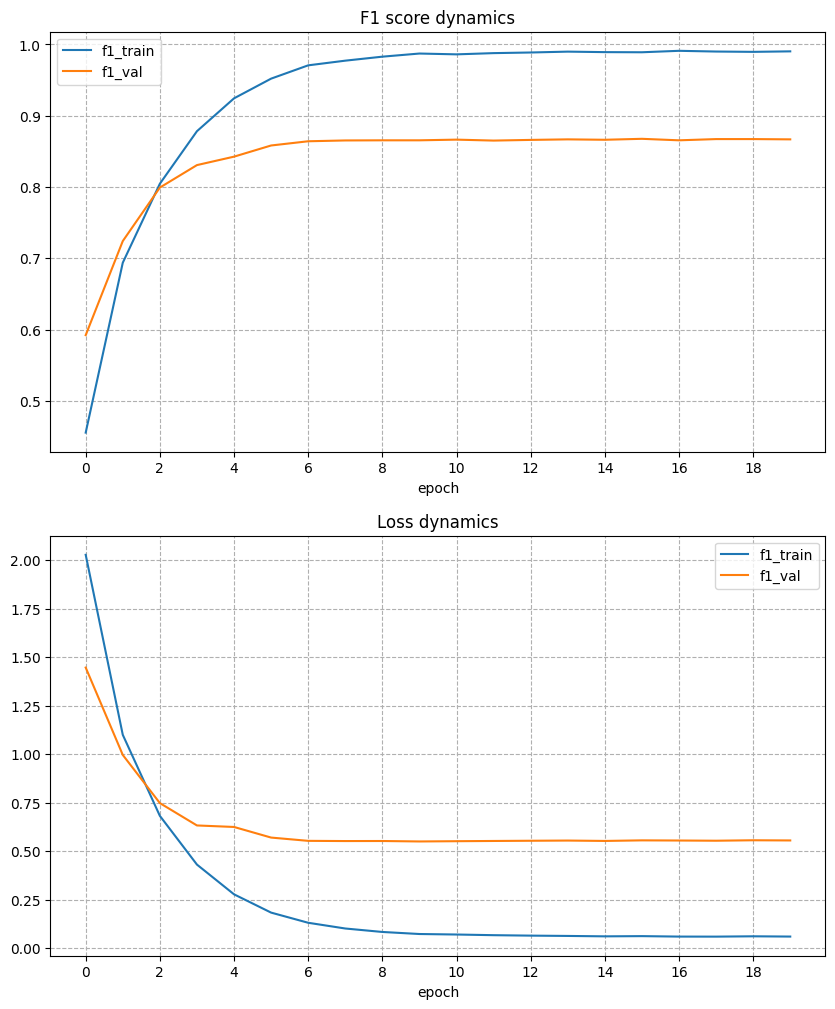

In [ ]:
plot_training(f1_values, loss_values)

In [ ]:
# сохраняем модель
torch.save(model_big_cnn.state_dict(), 'dropout_cnn_weights.pth')
torch.save(model_big_cnn, 'entire_dropout_model_cnn.pth')

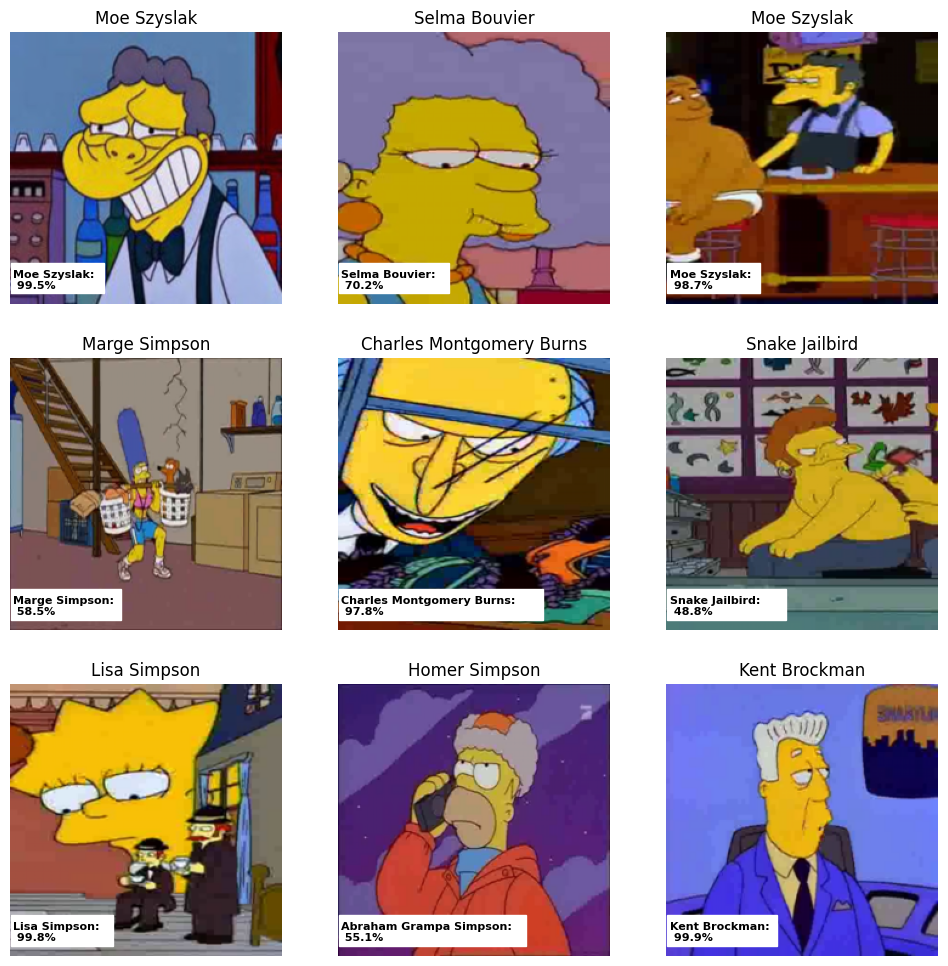

In [ ]:
show_images2(n_rows = 3, n_cols = 3, dataset = val_dataset, model = model_big_cnn)

In [ ]:
predicted_numeric_labels = predict(model_big_cnn, test_loader)
predicted_text_labels = label_encoder.inverse_transform(predicted_numeric_labels)

Test mode...


  0%|          | 0/16 [00:00<?, ?it/s]

In [ ]:
modified_submission = pd.DataFrame({'Id': [path.name for path in test_files], 'Expected': predicted_text_labels})
modified_submission.head()

,Id,Expected
0,img0.jpg,nelson_muntz
1,img1.jpg,bart_simpson
2,img10.jpg,ned_flanders
3,img100.jpg,chief_wiggum
4,img101.jpg,apu_nahasapeemapetilon


In [ ]:
modified_submission.to_csv('dropout_baseline.csv', index=False)

Эта модель дала качество 0.965. Попробуем использовать модель ResNet18 как предобученную, так и обучим сами.

In [ ]:
import torchvision.models as models
from torchvision.models import resnet18

In [ ]:
# предобученная модель
model_resnet = resnet18(weights=models.ResNet18_Weights.DEFAULT)
model_resnet

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
class ResNet(nn.Module):
    def __init__(self, n_classes, pretrained: bool = False, layer3: bool = False, optimizer_type='Adam') -> None:
        super().__init__()
        self.pretrained = pretrained
        self.scheduler_func = lambda epoch: 0.65 ** epoch

        if pretrained:
            self.model = resnet18(weights=models.ResNet18_Weights.DEFAULT)

            # замораживаем все веса
            for param in self.model.parameters():
                param.requires_grad = False

            self.model.fc = nn.Linear(in_features=512, out_features=n_classes)
            for param in self.model.fc.parameters():
                param.requires_grad = True

            for param in self.model.layer4.parameters():
                param.requires_grad = True

            if layer3:
                for param in self.model.layer3.parameters():
                    param.requires_grad = True

            if optimizer_type == 'AdamW':
                self.optimizer = torch.optim.AdamW(self.model.parameters(), lr=0.01)

            self.optimizer = torch.optim.Adam(self.model.parameters(), lr=0.01)
            self.scheduler = torch.optim.lr_scheduler.LambdaLR(self.optimizer, self.scheduler_func)
        else:
            self.model = resnet18(weights=None)
            self.model.fc = nn.Linear(in_features=512, out_features=n_classes)
            if optimizer_type == 'AdamW':
                self.optimizer = torch.optim.AdamW(self.model.parameters(), lr=0.01)
            self.optimizer = torch.optim.Adam(self.model.parameters(), lr=0.01)
            self.scheduler = torch.optim.lr_scheduler.LambdaLR(self.optimizer, self.scheduler_func)

    def forward(self, x) -> torch.Tensor:
        preds = self.model(x)
        return preds

In [ ]:
model_resnet = ResNet(n_classes=len(np.unique(train_val_labels)), pretrained=False)
model_resnet.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = model_resnet.optimizer
scheduler = model_resnet.scheduler

In [ ]:
max_epochs = 20
f1_values, loss_values, train_values, val_values = train_func(model=model_resnet, num_epochs=max_epochs, dataloaders=loaders, \
                                                              optimizer=optimizer, loss_func=criterion, lr_scheduler=scheduler)


Epoch: 1


100%|██████████| 246/246 [01:27<00:00,  2.81it/s]



F1_train: 0.22275304159500606



100%|██████████| 82/82 [00:15<00:00,  5.18it/s]



F1_val: 0.3716087122659534


Epoch: 2


100%|██████████| 246/246 [01:29<00:00,  2.75it/s]



F1_train: 0.5500987324033378



100%|██████████| 82/82 [00:16<00:00,  5.02it/s]



F1_val: 0.5953381734810852


Epoch: 3


100%|██████████| 246/246 [01:27<00:00,  2.82it/s]



F1_train: 0.7191540862475317



100%|██████████| 82/82 [00:15<00:00,  5.25it/s]



F1_val: 0.7340466182651891


Epoch: 4


100%|██████████| 246/246 [01:26<00:00,  2.85it/s]



F1_train: 0.8099878973183006



100%|██████████| 82/82 [00:15<00:00,  5.25it/s]



F1_val: 0.800152846771112


Epoch: 5


100%|██████████| 246/246 [01:27<00:00,  2.80it/s]



F1_train: 0.8673800879036881



100%|██████████| 82/82 [00:15<00:00,  5.20it/s]



F1_val: 0.8226977455101261


Epoch: 6


100%|██████████| 246/246 [01:29<00:00,  2.76it/s]



F1_train: 0.9087839989808268



100%|██████████| 82/82 [00:15<00:00,  5.27it/s]



F1_val: 0.8519296904852885


Epoch: 7


100%|██████████| 246/246 [01:30<00:00,  2.71it/s]



F1_train: 0.9394228931779094



100%|██████████| 82/82 [00:15<00:00,  5.21it/s]



F1_val: 0.8700802445548338


Epoch: 8


100%|██████████| 246/246 [01:30<00:00,  2.71it/s]



F1_train: 0.9596789604433403



100%|██████████| 82/82 [00:16<00:00,  5.12it/s]



F1_val: 0.8830722200993504


Epoch: 9


100%|██████████| 246/246 [01:30<00:00,  2.73it/s]



F1_train: 0.9717816421428116



100%|██████████| 82/82 [00:15<00:00,  5.19it/s]



F1_val: 0.8865112724493696


Epoch: 10


100%|██████████| 246/246 [01:31<00:00,  2.70it/s]



F1_train: 0.9800624243582394



100%|██████████| 82/82 [00:15<00:00,  5.14it/s]



F1_val: 0.8910966755827283


Epoch: 11


100%|██████████| 246/246 [01:29<00:00,  2.74it/s]



F1_train: 0.9858589719090388



100%|██████████| 82/82 [00:15<00:00,  5.22it/s]



F1_val: 0.892434084829958


Epoch: 12


100%|██████████| 246/246 [01:30<00:00,  2.71it/s]



F1_train: 0.9885979998726033



100%|██████████| 82/82 [00:15<00:00,  5.15it/s]



F1_val: 0.8939625525410776


Epoch: 13


100%|██████████| 246/246 [01:29<00:00,  2.74it/s]



F1_train: 0.9902541563156889



100%|██████████| 82/82 [00:15<00:00,  5.22it/s]



F1_val: 0.8918609094382881


Epoch: 14


100%|██████████| 246/246 [01:30<00:00,  2.72it/s]



F1_train: 0.9910822345372317



100%|██████████| 82/82 [00:15<00:00,  5.20it/s]



F1_val: 0.8939625525410776


Epoch: 15


100%|██████████| 246/246 [01:30<00:00,  2.73it/s]



F1_train: 0.9922925027071788



100%|██████████| 82/82 [00:15<00:00,  5.27it/s]



F1_val: 0.8943446694688575


Epoch: 16


100%|██████████| 246/246 [01:30<00:00,  2.72it/s]



F1_train: 0.9911459328619657



100%|██████████| 82/82 [00:15<00:00,  5.20it/s]



F1_val: 0.8958731371799771


Epoch: 17


100%|██████████| 246/246 [01:30<00:00,  2.71it/s]



F1_train: 0.9928020893050513



100%|██████████| 82/82 [00:15<00:00,  5.23it/s]



F1_val: 0.8952999617883072


Epoch: 18


100%|██████████| 246/246 [01:29<00:00,  2.74it/s]



F1_train: 0.9919740110835085



100%|██████████| 82/82 [00:15<00:00,  5.29it/s]



F1_val: 0.8943446694688575


Epoch: 19


100%|██████████| 246/246 [01:29<00:00,  2.76it/s]



F1_train: 0.9922288043824448



100%|██████████| 82/82 [00:15<00:00,  5.26it/s]



F1_val: 0.8951089033244173


Epoch: 20


100%|██████████| 246/246 [01:29<00:00,  2.75it/s]



F1_train: 0.9928020893050513



100%|██████████| 82/82 [00:15<00:00,  5.23it/s]


F1_val: 0.8949178448605273



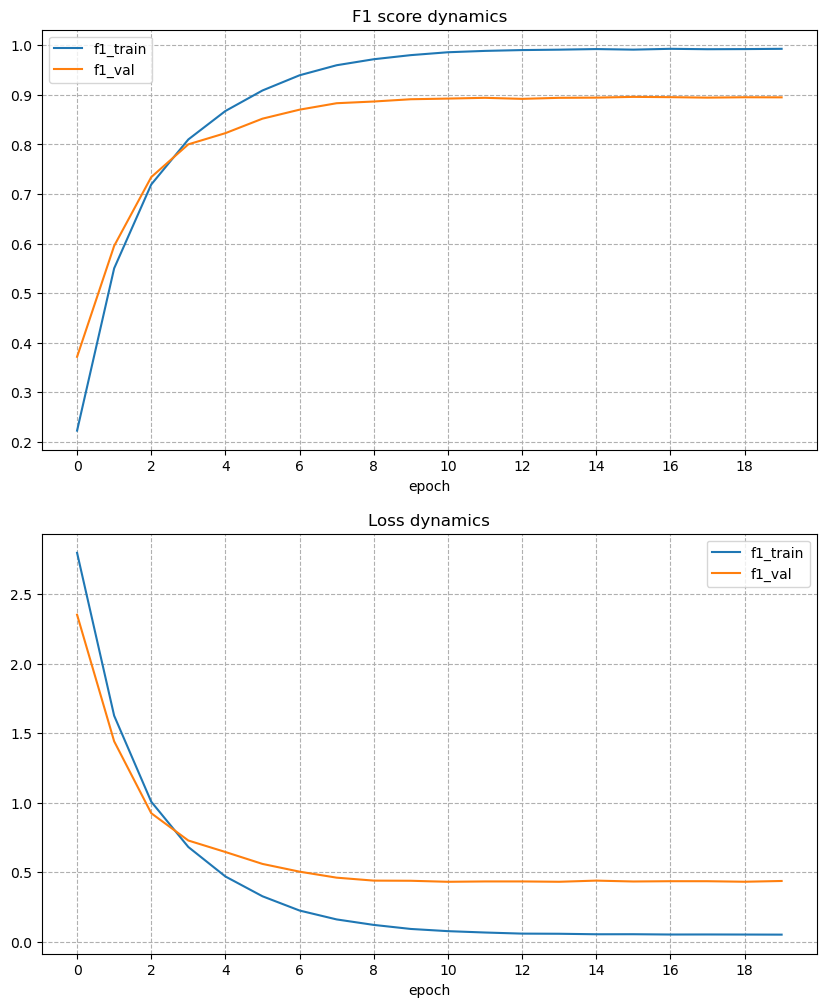

In [ ]:
plot_training(f1_values=f1_values, loss_values=loss_values, max_epochs=max_epochs)

In [ ]:
# сохраняем веса модели
torch.save(model_resnet.state_dict(), 'resnet_weights.pth')

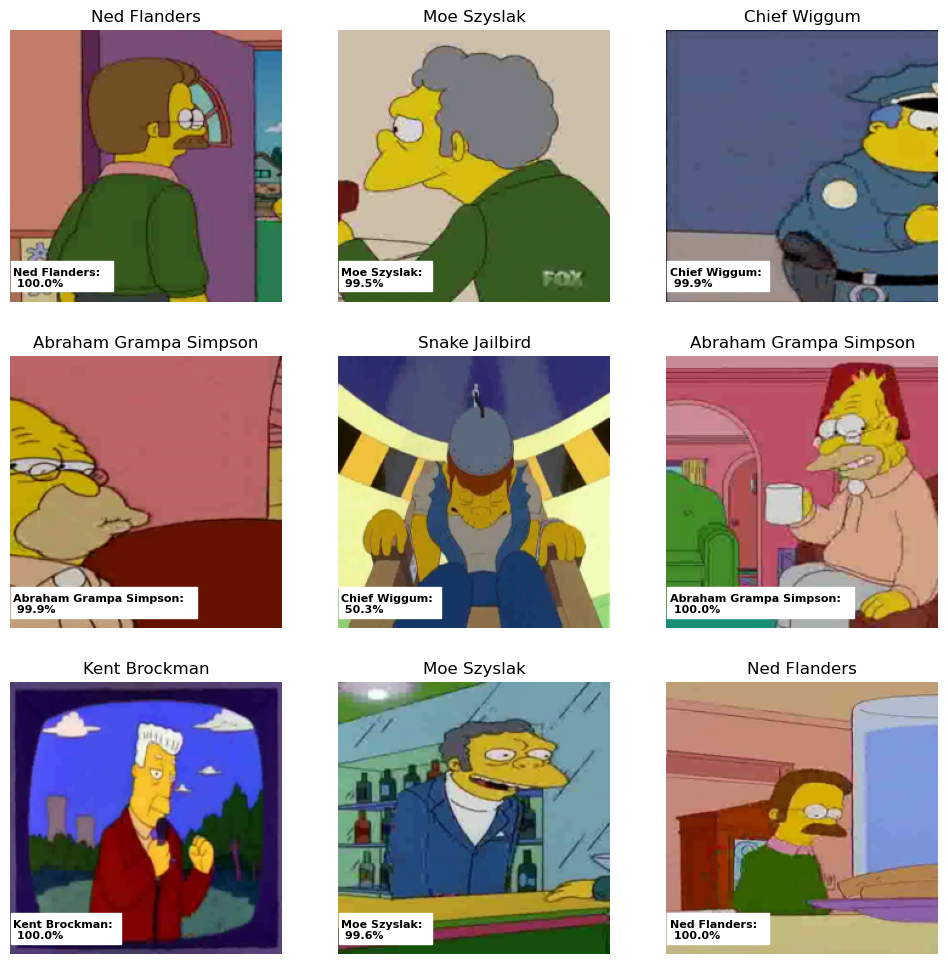

In [ ]:
show_images2(n_rows = 3, n_cols = 3, dataset = val_dataset, model = model_resnet)

In [ ]:
predicted_numeric_labels = predict(model_resnet, test_loader)
predicted_text_labels = label_encoder.inverse_transform(predicted_numeric_labels)

Test mode...


  0%|          | 0/16 [00:00<?, ?it/s]

In [ ]:
modified_submission = pd.DataFrame({'Id': [path.name for path in test_files], 'Expected': predicted_text_labels})
modified_submission.head()

,Id,Expected
0,img0.jpg,nelson_muntz
1,img1.jpg,bart_simpson
2,img10.jpg,ned_flanders
3,img100.jpg,chief_wiggum
4,img101.jpg,apu_nahasapeemapetilon


In [ ]:
modified_submission.to_csv('resnet_baseline.csv', index=False)

Непредобученная модель ResNet18 дает пока что лучшее качество на тесте: 0.968

Теперь попробуем дообучить layer4 и fc слои предобученной модели.

In [ ]:
model_resnet_pretrained = ResNet(n_classes=len(np.unique(train_val_labels)), pretrained=True)
model_resnet_pretrained.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = model_resnet_pretrained.optimizer
scheduler = model_resnet_pretrained.scheduler

In [ ]:
max_epochs = 15
f1_values, loss_values, train_values, val_values = train_func(model=model_resnet_pretrained, num_epochs=max_epochs, dataloaders=loaders, \
                                                              optimizer=optimizer, loss_func=criterion, lr_scheduler=scheduler)


Epoch: 1


100%|██████████| 246/246 [00:57<00:00,  4.25it/s]



F1_train: 0.7443149245174852



100%|██████████| 82/82 [00:16<00:00,  5.06it/s]



F1_val: 0.8328238440962935


Epoch: 2


100%|██████████| 246/246 [00:57<00:00,  4.30it/s]



F1_train: 0.915472323077903



100%|██████████| 82/82 [00:15<00:00,  5.33it/s]



F1_val: 0.9059992357661445


Epoch: 3


100%|██████████| 246/246 [00:56<00:00,  4.33it/s]



F1_train: 0.9638193515510542



100%|██████████| 82/82 [00:15<00:00,  5.27it/s]



F1_val: 0.9237676729079098


Epoch: 4


100%|██████████| 246/246 [00:58<00:00,  4.23it/s]



F1_train: 0.9881521115994649



100%|██████████| 82/82 [00:15<00:00,  5.36it/s]



F1_val: 0.934849063813527


Epoch: 5


100%|██████████| 246/246 [00:56<00:00,  4.34it/s]



F1_train: 0.9972609720364355



100%|██████████| 82/82 [00:15<00:00,  5.35it/s]



F1_val: 0.9430645777607948


Epoch: 6


100%|██████████| 246/246 [00:58<00:00,  4.22it/s]



F1_train: 0.9992993184279253



100%|██████████| 82/82 [00:15<00:00,  5.25it/s]



F1_val: 0.9453572793274742


Epoch: 7


100%|██████████| 246/246 [00:57<00:00,  4.26it/s]



F1_train: 0.9998089050257978



100%|██████████| 82/82 [00:15<00:00,  5.19it/s]



F1_val: 0.9474589224302636


Epoch: 8


100%|██████████| 246/246 [00:56<00:00,  4.33it/s]



F1_train: 0.9998726033505319



100%|██████████| 82/82 [00:15<00:00,  5.35it/s]



F1_val: 0.9486052732136033


Epoch: 9


100%|██████████| 246/246 [00:56<00:00,  4.35it/s]



F1_train: 0.9996815083763297



100%|██████████| 82/82 [00:15<00:00,  5.36it/s]



F1_val: 0.9468857470385939


Epoch: 10


100%|██████████| 246/246 [00:56<00:00,  4.38it/s]



F1_train: 0.9999363016752659



100%|██████████| 82/82 [00:15<00:00,  5.38it/s]



F1_val: 0.9478410393580435


Epoch: 11


100%|██████████| 246/246 [00:56<00:00,  4.36it/s]



F1_train: 0.9998726033505319



100%|██████████| 82/82 [00:15<00:00,  5.36it/s]



F1_val: 0.9487963316774933


Epoch: 12


100%|██████████| 246/246 [00:56<00:00,  4.36it/s]



F1_train: 0.9999363016752659



100%|██████████| 82/82 [00:15<00:00,  5.39it/s]



F1_val: 0.9489873901413832


Epoch: 13


100%|██████████| 246/246 [00:56<00:00,  4.37it/s]



F1_train: 0.9999363016752659



100%|██████████| 82/82 [00:15<00:00,  5.43it/s]



F1_val: 0.9480320978219335


Epoch: 14


100%|██████████| 246/246 [00:56<00:00,  4.37it/s]



F1_train: 1.0



100%|██████████| 82/82 [00:15<00:00,  5.40it/s]



F1_val: 0.9493695070691631


Epoch: 15


100%|██████████| 246/246 [00:56<00:00,  4.37it/s]



F1_train: 0.9999363016752659



100%|██████████| 82/82 [00:15<00:00,  5.35it/s]


F1_val: 0.9486052732136033



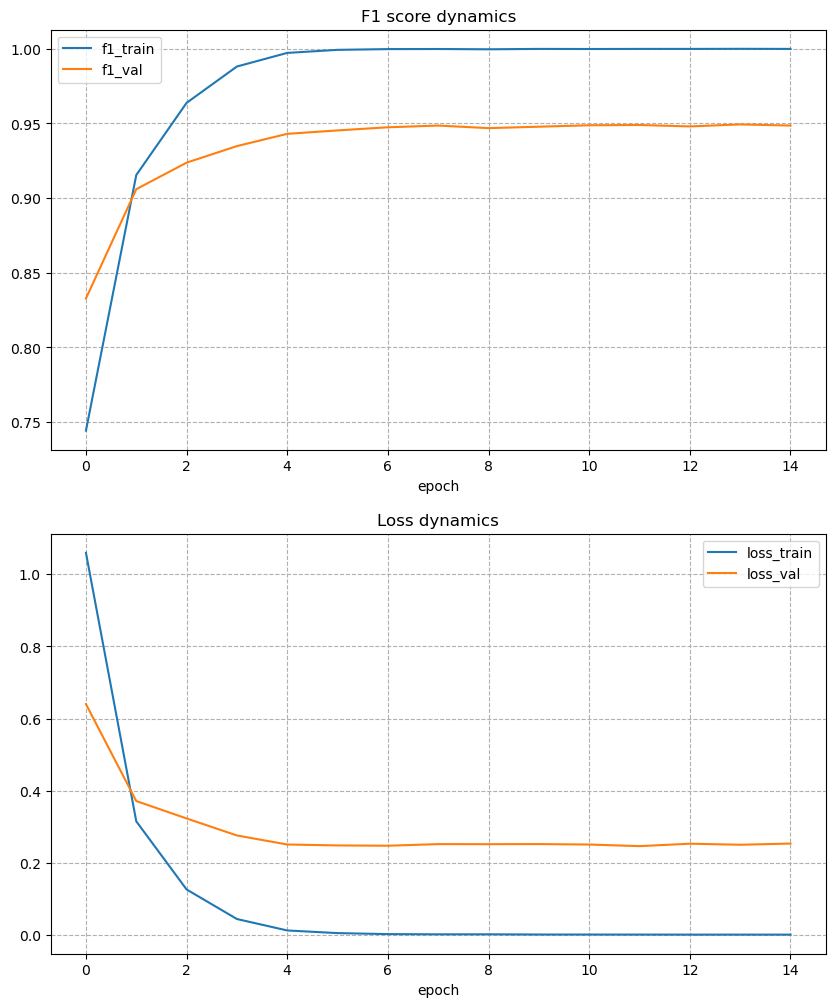

In [ ]:
plot_training(f1_values=f1_values, loss_values=loss_values, max_epochs=max_epochs)

In [ ]:
torch.save(model_resnet_pretrained.state_dict(), 'resnet_pretrained_weights.pth')

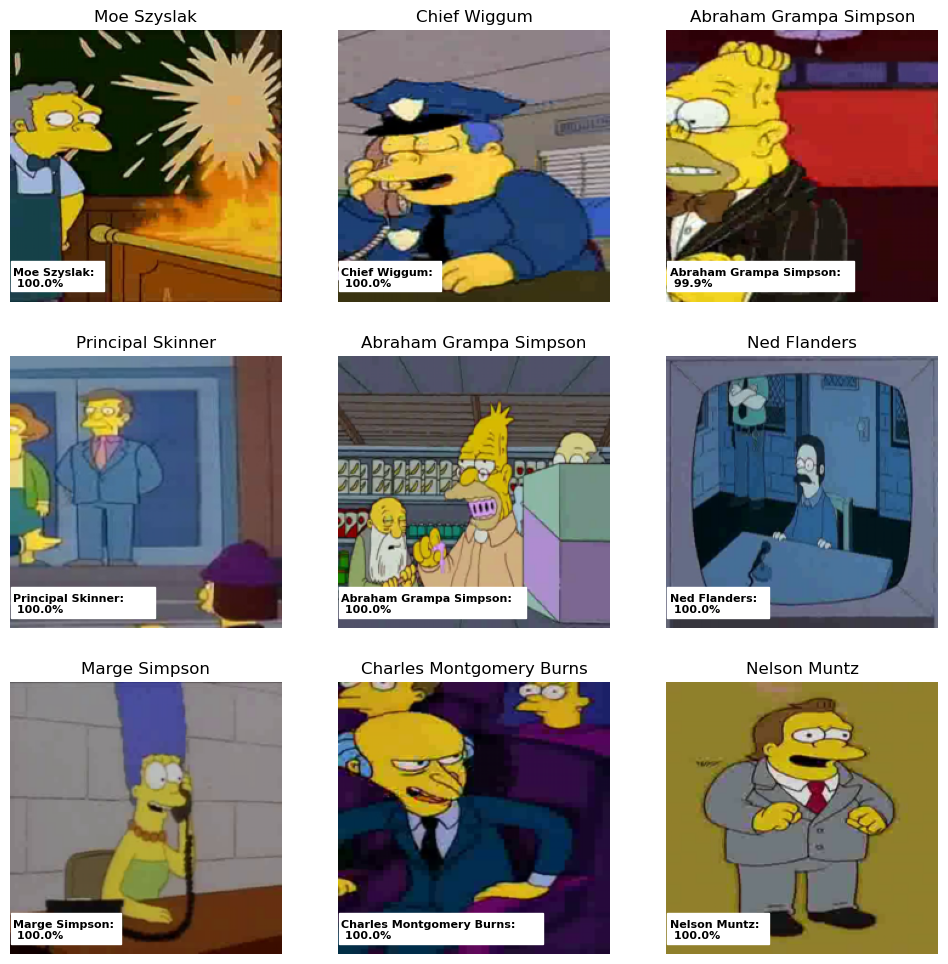

In [ ]:
show_images2(n_rows = 3, n_cols = 3, dataset = val_dataset, model = model_resnet_pretrained)

In [ ]:
predicted_numeric_labels = predict(model_resnet_pretrained, test_loader)
predicted_text_labels = label_encoder.inverse_transform(predicted_numeric_labels)

Test mode...


  0%|          | 0/16 [00:00<?, ?it/s]

In [ ]:
modified_submission = pd.DataFrame({'Id': [path.name for path in test_files], 'Expected': predicted_text_labels})
modified_submission.to_csv('resnet_pretrained_baseline.csv', index=False)
modified_submission.head()

,Id,Expected
0,img0.jpg,nelson_muntz
1,img1.jpg,bart_simpson
2,img10.jpg,ned_flanders
3,img100.jpg,chief_wiggum
4,img101.jpg,apu_nahasapeemapetilon


Попробуем использовать оптимизатор AdamW.

In [ ]:
model_resnet_pretrained_adamw = ResNet(n_classes=len(np.unique(train_val_labels)), pretrained=True, optimizer_type='AdamW')
model_resnet_pretrained_adamw.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = model_resnet_pretrained_adamw.optimizer
scheduler = model_resnet_pretrained_adamw.scheduler

In [ ]:
max_epochs = 15
f1_values, loss_values, train_values, val_values = train_func(model=model_resnet_pretrained_adamw, num_epochs=max_epochs, dataloaders=loaders, \
                                                              optimizer=optimizer, loss_func=criterion, lr_scheduler=scheduler)


Epoch: 1


100%|██████████| 246/246 [00:56<00:00,  4.38it/s]



F1_train: 0.7534874832791898



100%|██████████| 82/82 [00:15<00:00,  5.40it/s]



F1_val: 0.8668322506687046


Epoch: 2


100%|██████████| 246/246 [00:56<00:00,  4.33it/s]



F1_train: 0.9176380661188611



100%|██████████| 82/82 [00:15<00:00,  5.33it/s]



F1_val: 0.9050439434466947


Epoch: 3


100%|██████████| 246/246 [00:56<00:00,  4.33it/s]



F1_train: 0.9654118096694057



100%|██████████| 82/82 [00:15<00:00,  5.41it/s]



F1_val: 0.9277799006495988


Epoch: 4


100%|██████████| 246/246 [00:56<00:00,  4.35it/s]



F1_train: 0.9884069048984012



100%|██████████| 82/82 [00:15<00:00,  5.38it/s]



F1_val: 0.9401987008024455


Epoch: 5


100%|██████████| 246/246 [00:56<00:00,  4.37it/s]



F1_train: 0.996751385438563



100%|██████████| 82/82 [00:15<00:00,  5.36it/s]



F1_val: 0.9466946885747038


Epoch: 6


100%|██████████| 246/246 [00:56<00:00,  4.37it/s]



F1_train: 0.9992356201031913



100%|██████████| 82/82 [00:15<00:00,  5.38it/s]



F1_val: 0.9487963316774933


Epoch: 7


100%|██████████| 246/246 [00:56<00:00,  4.38it/s]



F1_train: 0.9995541117268616



100%|██████████| 82/82 [00:14<00:00,  5.47it/s]



F1_val: 0.945930454719144


Epoch: 8


100%|██████████| 246/246 [00:55<00:00,  4.43it/s]



F1_train: 0.9999363016752659



100%|██████████| 82/82 [00:15<00:00,  5.42it/s]



F1_val: 0.946503630110814


Epoch: 9


100%|██████████| 246/246 [00:55<00:00,  4.40it/s]



F1_train: 0.9998726033505319



100%|██████████| 82/82 [00:15<00:00,  5.39it/s]



F1_val: 0.9472678639663737


Epoch: 10


100%|██████████| 246/246 [00:56<00:00,  4.34it/s]



F1_train: 0.9999363016752659



100%|██████████| 82/82 [00:15<00:00,  5.36it/s]



F1_val: 0.9484142147497134


Epoch: 11


100%|██████████| 246/246 [00:56<00:00,  4.36it/s]



F1_train: 0.9998726033505319



100%|██████████| 82/82 [00:15<00:00,  5.36it/s]



F1_val: 0.9486052732136033


Epoch: 12


100%|██████████| 246/246 [00:56<00:00,  4.34it/s]



F1_train: 0.9998726033505319



100%|██████████| 82/82 [00:15<00:00,  5.35it/s]



F1_val: 0.9493695070691631


Epoch: 13


100%|██████████| 246/246 [00:56<00:00,  4.34it/s]



F1_train: 0.9999363016752659



100%|██████████| 82/82 [00:15<00:00,  5.32it/s]



F1_val: 0.9482231562858234


Epoch: 14


100%|██████████| 246/246 [00:56<00:00,  4.34it/s]



F1_train: 0.9998726033505319



100%|██████████| 82/82 [00:15<00:00,  5.34it/s]



F1_val: 0.9489873901413832


Epoch: 15


100%|██████████| 246/246 [00:56<00:00,  4.34it/s]



F1_train: 0.9997452067010638



100%|██████████| 82/82 [00:15<00:00,  5.18it/s]


F1_val: 0.9487963316774933



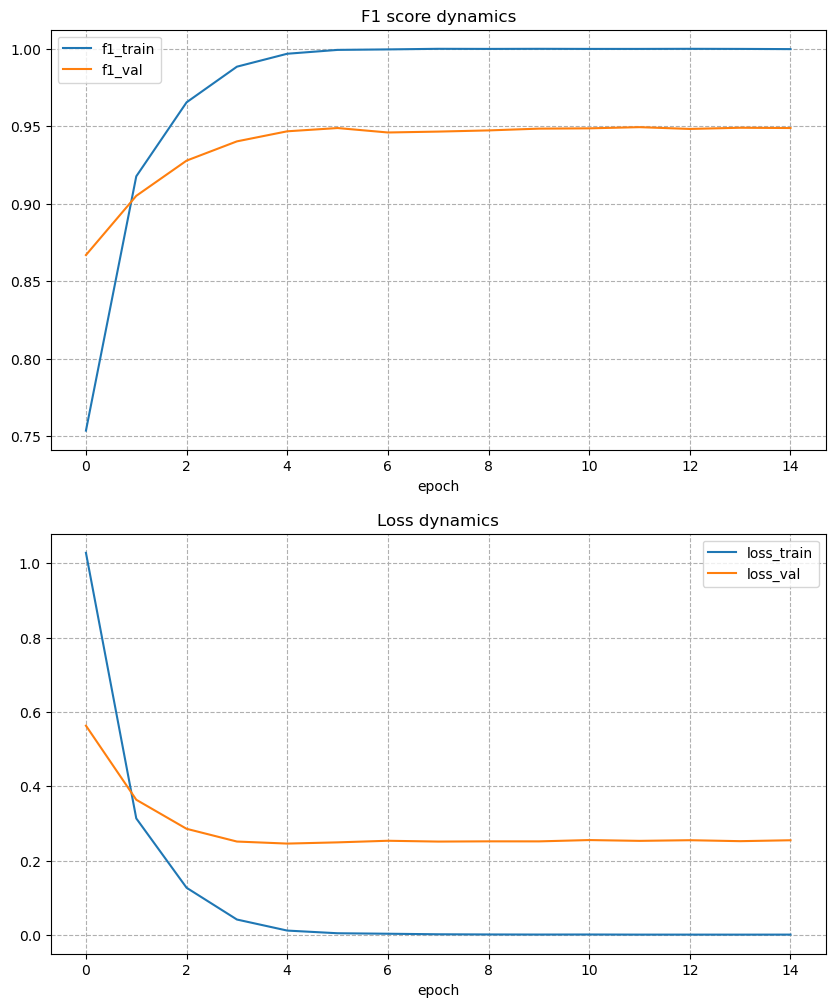

In [ ]:
plot_training(f1_values=f1_values, loss_values=loss_values, max_epochs=max_epochs)

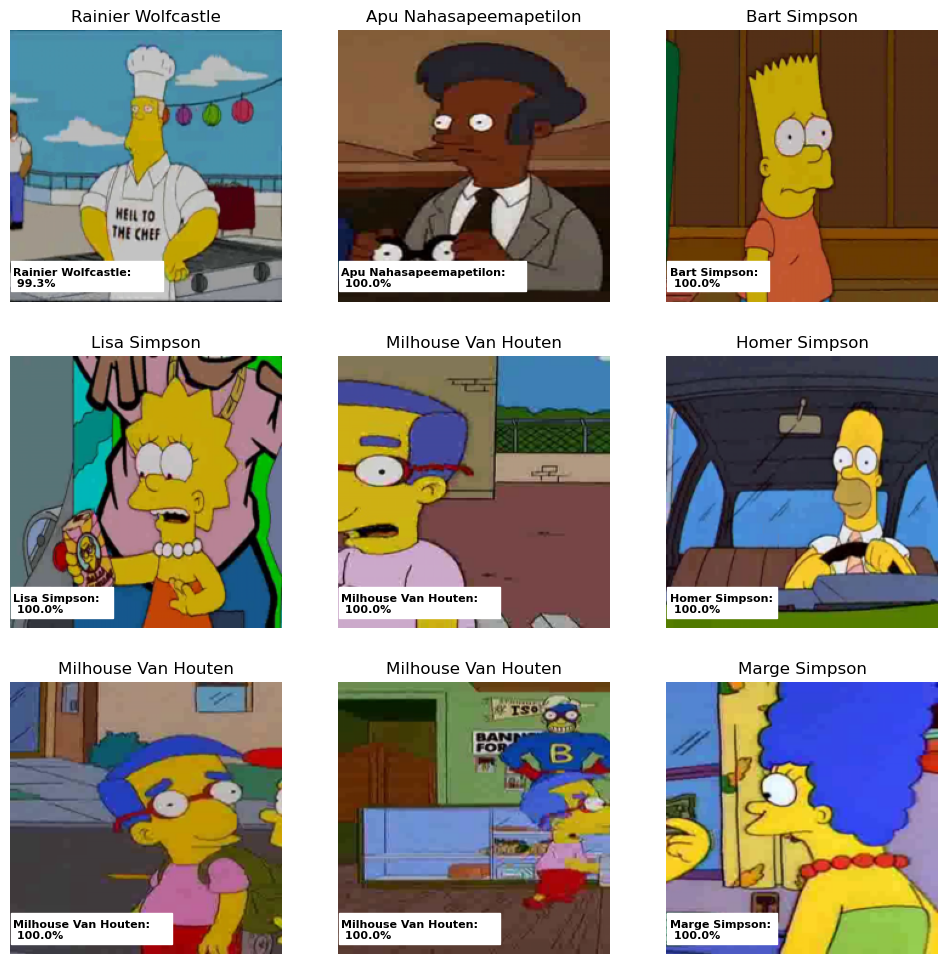

In [ ]:
show_images2(n_rows = 3, n_cols = 3, dataset = val_dataset, model = model_resnet_pretrained_adamw)

In [ ]:
torch.save(model_resnet_pretrained_adamw.state_dict(), 'resnet_pretrained_adamw_weights.pth')

In [ ]:
predicted_numeric_labels = predict(model_resnet_pretrained_adamw, test_loader)
predicted_text_labels = label_encoder.inverse_transform(predicted_numeric_labels)

Test mode...


  0%|          | 0/16 [00:00<?, ?it/s]

In [ ]:
modified_submission = pd.DataFrame({'Id': [path.name for path in test_files], 'Expected': predicted_text_labels})
modified_submission.to_csv('resnet_pretrained_adamw_baseline.csv', index=False)
modified_submission.head()

,Id,Expected
0,img0.jpg,nelson_muntz
1,img1.jpg,bart_simpson
2,img10.jpg,ned_flanders
3,img100.jpg,chief_wiggum
4,img101.jpg,apu_nahasapeemapetilon


Эта модель дает лучшее качество на тесте: 0.986.

Попробуем также обучить и layer3 в архитектуре ResNet18.

In [ ]:
model_resnet_pretrained_new = ResNet(n_classes=len(np.unique(train_val_labels)), pretrained=True, layer3=True)
model_resnet_pretrained_new.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = model_resnet_pretrained_new.optimizer
scheduler = model_resnet_pretrained_new.scheduler

In [ ]:
max_epochs = 10
f1_values, loss_values, train_values, val_values = train_func(model=model_resnet_pretrained_new, num_epochs=max_epochs, dataloaders=loaders, \
                                                              optimizer=optimizer, loss_func=criterion, lr_scheduler=scheduler)


Epoch: 1


100%|██████████| 246/246 [01:03<00:00,  3.87it/s]



F1_train: 0.41225555767883304



100%|██████████| 82/82 [00:15<00:00,  5.34it/s]



F1_val: 0.5590370653419946


Epoch: 2


100%|██████████| 246/246 [01:03<00:00,  3.90it/s]



F1_train: 0.8159755398433021



100%|██████████| 82/82 [00:15<00:00,  5.27it/s]



F1_val: 0.8509743981658388


Epoch: 3


100%|██████████| 246/246 [01:04<00:00,  3.84it/s]



F1_train: 0.9171921778457227



100%|██████████| 82/82 [00:15<00:00,  5.44it/s]



F1_val: 0.880779518532671


Epoch: 4


100%|██████████| 246/246 [01:02<00:00,  3.91it/s]



F1_train: 0.9583412956239251



100%|██████████| 82/82 [00:15<00:00,  5.41it/s]



F1_val: 0.9157432174245319


Epoch: 5


100%|██████████| 246/246 [01:02<00:00,  3.94it/s]



F1_train: 0.9829288489712721



100%|██████████| 82/82 [00:15<00:00,  5.37it/s]



F1_val: 0.9317921283912878


Epoch: 6


100%|██████████| 246/246 [01:04<00:00,  3.81it/s]



F1_train: 0.9923562010319129



100%|██████████| 82/82 [00:15<00:00,  5.30it/s]



F1_val: 0.9337027130301873


Epoch: 7


100%|██████████| 246/246 [01:03<00:00,  3.88it/s]



F1_train: 0.9976431619848398



100%|██████████| 82/82 [00:14<00:00,  5.51it/s]



F1_val: 0.9359954145968666


Epoch: 8


100%|██████████| 246/246 [01:02<00:00,  3.92it/s]



F1_train: 0.9993630167526594



100%|██████████| 82/82 [00:15<00:00,  5.42it/s]



F1_val: 0.9361864730607566


Epoch: 9


100%|██████████| 246/246 [01:02<00:00,  3.93it/s]



F1_train: 0.9995541117268616



100%|██████████| 82/82 [00:15<00:00,  5.41it/s]



F1_val: 0.9375238823079862


Epoch: 10


100%|██████████| 246/246 [01:02<00:00,  3.94it/s]



F1_train: 0.9994267150773934



100%|██████████| 82/82 [00:15<00:00,  5.43it/s]


F1_val: 0.9363775315246465



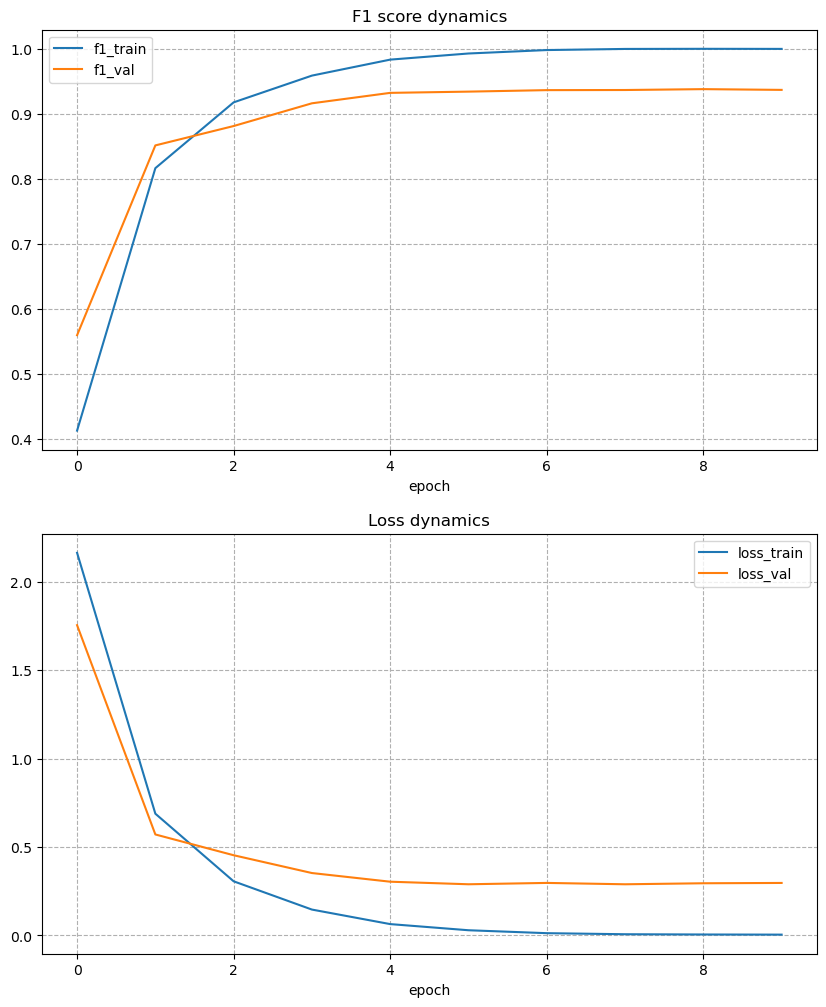

In [ ]:
plot_training(f1_values=f1_values, loss_values=loss_values, max_epochs=max_epochs)

Исходя из валидации видно, что предобученная модель, которую дообучили на последнем fc слое и слое layer4 показывает качество чуть лучше чем эта.

Финальное итоговое качество на тесте: 0.986.